# LSST Y1 × DESI: where model A breaks, and models A and B against $k_\mathrm{max}$

The forecast fits the DESI band powers $C_\ell^{gg}$ of thin redshift bins,
computed without the Limber approximation, on four bin layouts: bins of equal
comoving width $\Delta d_\mathrm{com} = 62$ Mpc, and bins of fixed redshift
width $\Delta z = 0.02$, $0.05$ and $0.2$. `EXAMPLE_EVALUATE_FISHER_MODEL_A.ipynb`
(the model A notebook) forecasts with the one-loop bias model A of
`notes/higher_order_bias` at one scale cut. This notebook scans the cut for
three results:

1. the $k_\mathrm{max}$ at which model A breaks, when the truth carries the
   freedom that model B adds (section 7);
2. the figures of merit of models A and B against $k_\mathrm{max}$ (section 6);
3. the data of the paper's figure of the FoM against $k_\mathrm{max}$
   (section 8).

**Symbols.** $D(z)$ is the linear growth factor with $D(0) = 1$;
$w(a) = w_0 + w_a(1 - a)$ the dark-energy equation of state, with $a$ the scale
factor; $\Omega_m$ the matter density today in units of the critical density;
$A_s$ the amplitude of the primordial curvature power spectrum, sampled as
`As_1e9` $= 10^9 A_s$. ${\rm FoM}(w_0, w_a) = [\det \mathrm{Cov}(w_0, w_a)]^{-1/2}$
is the inverse area of the marginalized $(w_0, w_a)$ error ellipse, and
${\rm FoM}(\Omega_m, 10^9 A_s)$ the same for $(\Omega_m, 10^9 A_s)$. $\sigma$ is
a parameter's marginalized one-sigma error.

**Model A** (as in the model A notebook). The linear bias $b_{1,i}$ of bin $i$
is free per bin under a linear-bias prior. The quadratic bias $b_2$ and the
tidal bias $b_{s^2}$ follow it through calibrations plus one offset per tracer
group $g$: $b_{2,i} = b_2^\mathrm{L}(b_{1,i}) + \Delta_{2,g}$, with
$b_2^\mathrm{L}$ the Lazeyras et al. fit (arXiv:1511.01096), and
$b_{s^2,i} = -\tfrac{4}{7}(b_{1,i} - 1) + \Delta_{s,g}$ (co-evolution). Each group
also carries a $k^2$ counterterm $\alpha_0$, in $h^{-2}\,\mathrm{Mpc}^2$, a
white noise $\mathrm{SN}_0$ beyond Poisson, in units of the bin's Poisson power
$1/\bar n_i$ ($\bar n_i$ the tracer density), and the stochastic term
$\mathrm{SN}_2\,k^2\mu^2$, with $\mu$ the cosine of the angle to the line of
sight, in units of $f_\mathrm{sat}\sigma_\mathrm{sat}^2/\bar n_i$: $f_\mathrm{sat}$ the
satellite fraction and $\sigma_\mathrm{sat}$ the satellites' velocity dispersion
in distance units (DESI DR1 values per sample, `SN2_UNIT` of
`likelihood/desi_cl.py`; not the Fingers-of-God dispersion $\sigma_v$ that
smooths the bins' redshift distributions). $\mathrm{SN}_2$ projects through the
radial derivatives of the bin kernels, so adjacent bins, which share an edge,
get an anticorrelated cross term that $\mathrm{SN}_0$ cannot mimic.

**Model B** keeps that linear sector and the two stochastic terms, widens the
two offsets and adds the radial counterterm $\alpha_2$ per group, in the DESI
DR1 convention: the counterterm density is
$\tfrac{1}{2}(b_1\alpha_0 + f\mu^2\alpha_2)\,k^2\delta_\mathrm{L}$, with $f$ the
linear growth rate and $\delta_\mathrm{L}$ the linear density contrast.

Model B here carries no redshift-space one-loop terms; CosmoLike has none. The
Gaussian priors are centered on zero:

| parameter | model A | model B |
|---|---|---|
| $\Delta_2$ | 1.0 | 2.0 |
| $\Delta_s$ | 0.5 | 1.0 |
| $\alpha_0$ [$h^{-2}\,\mathrm{Mpc}^2$] | $0.5/k_\mathrm{max}^2$ | $0.5/k_\mathrm{max}^2$ |
| $\alpha_2$ [$h^{-2}\,\mathrm{Mpc}^2$] | none | $0.5/k_\mathrm{max}^2$ |
| $\mathrm{SN}_0$ [$1/\bar n_i$] | 2 | 2 |
| $\mathrm{SN}_2$ [$f_\mathrm{sat}\sigma_\mathrm{sat}^2/\bar n_i$] | 5 | 5 |

The counterterm widths are the DESI rule of a 50% correction at the cut,
evaluated at every cut: $88.9\,h^{-2}\,\mathrm{Mpc}^2$ at
$k_\mathrm{max} = 0.075\,h/\mathrm{Mpc}$, DESI's $12.5$ at $0.2$.

**Variants.** Each model comes as a baseline variant, one offset, counterterm and
stochastic amplitude per group, and a pessimistic variant, in which
$\Delta_2$, $\Delta_s$, $\alpha_0$ and $\alpha_2$ also tilt linearly in redshift
across the group with flat priors on the tilts. $\mathrm{SN}_0$ and
$\mathrm{SN}_2$ never tilt: their Poisson part is known bin by bin. The code
labels are `'A baseline'`, `'A pessimistic'`, `'B baseline'` and
`'B pessimistic'`.

**Linear-bias priors.** The fits use three of the four priors of the
correlated-prior note, `notes/correlated_bias_prior_v2`: baseline, pessimistic
and free (code label `'independent'`). The growth-tied prior is omitted: it
fails that note's accuracy test, so its FoM means nothing.

**The scale cut.** Bin $i$ is cut at $k_\mathrm{max}/D(\bar z_i)$, with
$\bar z_i$ its mean redshift, by the non-Limber ultraviolet-fraction criterion
(arXiv:2603.13031): a band is kept while less than $\alpha = 0.05$ of it comes
from the power spectrum above that wavenumber, within the shipped mask. Every
$k_\mathrm{max}$ here is quoted at $z = 0$.

**Inputs and outputs.** The notebook reads, never writes, the model A
notebook's derivative caches and the linear notebook's scale cuts. It computes
the two model B templates once and caches them in `chains/`. It writes the
data of two figure folders of the correlated-prior note.

## 1. Set up Python and the Fisher module

Imports and the paths to CosmoLike and to the project's interface. The
project's Fisher module, imported as `fm`, builds the model A likelihood in
section 4, where the model B templates are computed.

In [1]:
import importlib
import inspect
import json
import os
import pickle
import subprocess
import sys
import time
# The OpenMP runtime reads OMP_NUM_THREADS when it starts, so the value is
# set before the Fisher module imports the compiled interface.
os.environ['OMP_NUM_THREADS'] = '8'
import numpy as np
import pandas as pd
import scipy.integrate
import scipy.linalg
import scipy.special
from IPython.display import Image, display

# start_cocoa.sh exports ROOTDIR, the Cocoa/ folder; the EXAMPLE yamls name
# their data and codes relative to it
ROOTDIR = os.environ['ROOTDIR']
os.chdir(ROOTDIR)

sys.path.insert(0, ROOTDIR + '/external_modules/code/cosmolike_core')
sys.path.insert(0, ROOTDIR + '/projects/lssty1xdesi/interface')
import cosmolike_lssty1xdesi_fisher as fm
print('Using the Fisher module at %s' % fm.__file__)
pd.set_option('display.float_format', '{:.4g}'.format)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 220)

Using the Fisher module at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/lssty1xdesi/interface/cosmolike_lssty1xdesi_fisher.py


## 2. The settings

- `COSMO`: the seven cosmological parameters ($10^9 A_s$, $n_s$, $H_0$,
  $\Omega_b$, $\Omega_m$, $w_0$, $w_a$), all with flat priors.
- `INVCOV_SCALE`: the DESI covariance is computed for 14,000 deg$^2$; its
  inverse is rescaled to the survey's 12,300 deg$^2$.
- `SCALE_CUTS_CACHE`: the linear notebook's ultraviolet-fraction cuts,
  `KMAX_CUTS` $= 0.05, 0.075, \ldots, 0.25\,h/\mathrm{Mpc}$ at $z = 0$.
- `LAYOUTS`: the four layouts on their model A example yamls, with the settings
  of the model A notebook. `MODEL_A_CACHE` and `MODEL_A_STEPS`: the model A
  derivative caches and the steps they were computed with; a cache made with
  other settings is refused.
- `FIXED_WIDTHS` and `COUNTERTERM_FRACTION`: the prior widths of the table
  above; `prior_widths` returns them at one cut.
- `ALPHA2_SETTER`, `ALPHA2_KEYWORD` and `A2_STEP`: the compiled interface's
  setter of the per-bin $\alpha_2$ (in $h^{-2}\,\mathrm{Mpc}^2$), its keyword,
  and the finite-difference step of section 4. `TEMPLATE_CACHE` and
  `RECOMPUTE_TEMPLATES`: the cache of the model B templates.
- `FIXED_TRUTHS`, `SHIFT_THRESHOLD`, `MISMATCH_TRUTHS`, `RANDOM_FAMILIES`,
  `SCATTER_DRAWS`, `SCATTER_SEED` and `ONE_SIGMA`: the truths of section 7, the
  threshold of its break point, $\sigma/3$, and the content of a $1\sigma$
  region, 68.3%.
- `LSST_Y1_SRD_FOM` $= 17.26$ and `LSST_Y1_SRD_FOM_OM_AS` $= 214.9$: the LSST Y1
  3x2pt references of the `lsst_y1` project, FoM$(w_0, w_a)$ and
  FoM$(\Omega_m, 10^9 A_s)$ from one Fisher matrix.
- `NOTE_PLOTS`: the correlated-prior note's plots folder, where section 8
  writes; `MODEL_A_LADDER`: the model A notebook's FoMs, which section 6 checks
  against.

In [2]:
PROJECT = 'projects/lssty1xdesi/'
CHAINS = ROOTDIR + '/projects/lssty1xdesi/chains/'
DESI_DATA = ROOTDIR + '/projects/lssty1xdesi/data/'
# the figures of this notebook go to the v2 note
NOTE_PLOTS = ROOTDIR + '/projects/lssty1xdesi/notes/correlated_bias_prior_v2/plots/'
# the model A notebook's FoMs at its cut (the cross-check of section 6)
MODEL_A_LADDER = NOTE_PLOTS + 'baseline_ladder/data.json'
COSMO = ['As_1e9', 'ns', 'H0', 'omegab', 'omegam', 'w0', 'wa']
# one footprint for every probe [deg^2]; the DESI covariance files are built
# at DESI_COV_AREA_DEG2
AREA_DEG2 = 12300.0
DESI_COV_AREA_DEG2 = 14000.0
INVCOV_SCALE = AREA_DEG2/DESI_COV_AREA_DEG2
H_MAIN = 0.02
# the UV-fraction cuts of the linear notebook: every k_max [h/Mpc at z = 0]
# with its kept bands per layout
SCALE_CUTS_CACHE = CHAINS + 'EXAMPLE_EVALUATE_FISHER_SCALE_CUTS.pkl'
# LSST Y1 3x2pt in real space, the SRD setup (lsst_y1 project): the FoM of
# (w0, wa) and of (Omega_m, 10^9 A_s) from the Fisher matrix of its
# EXAMPLE_EVALUATE2.ipynb (chains/EXAMPLE_EVALUATE2_FISHER_3x2pt.pkl)
LSST_Y1_SRD_FOM = 17.26
LSST_Y1_SRD_FOM_OM_AS = 214.9

# The four layouts at the model A notebook's settings (likelihood overrides
# and overall accuracy boost), on their model A example yamls. The entries
# must equal the model A notebook's: its caches store them and are refused
# when they differ.
LAYOUTS = {
    'Delta d_com = 62 Mpc': {
        'yaml': PROJECT + 'EXAMPLE_EVALUATE_MODEL_A1.yaml',
        'dataset': 'lssty1xdesi_desi_dr3',
        'bias_params': PROJECT + 'likelihood/params_desi.yaml',
        'overrides': {}, 'accuracy_boost': 1.0},
    'Delta z = 0.02': {
        'yaml': PROJECT + 'EXAMPLE_EVALUATE_MODEL_A2.yaml',
        'dataset': 'lssty1xdesi_desi_dr1_dz0p02',
        'bias_params': PROJECT + 'likelihood/params_desi_dr1_dz0p02.yaml',
        'overrides': {}, 'accuracy_boost': 1.0},
    'Delta z = 0.05': {
        'yaml': PROJECT + 'EXAMPLE_EVALUATE_MODEL_A3.yaml',
        'dataset': 'lssty1xdesi_desi_dr1_dz0p05',
        'bias_params': PROJECT + 'likelihood/params_desi_dr1_dz0p05.yaml',
        'overrides': {'nonlimber_accuracyboost': 32.0}, 'accuracy_boost': 1.0},
    'Delta z = 0.2': {
        'yaml': PROJECT + 'EXAMPLE_EVALUATE_MODEL_A4.yaml',
        'dataset': 'lssty1xdesi_desi_dr1_dz0p20',
        'bias_params': PROJECT + 'likelihood/params_desi_dr1_dz0p20.yaml',
        'overrides': {'nonlimber_accuracyboost': 64.0}, 'accuracy_boost': 3.0},
}
LAYOUT_LABELS = {'Delta d_com = 62 Mpc': r'$\Delta d_\mathrm{com} = 62$ Mpc',
                 'Delta z = 0.02': r'$\Delta z = 0.02$',
                 'Delta z = 0.05': r'$\Delta z = 0.05$',
                 'Delta z = 0.2': r'$\Delta z = 0.2$'}
LAYOUT_COLORS = {'Delta d_com = 62 Mpc': 'C0', 'Delta z = 0.02': 'C3',
                 'Delta z = 0.05': 'C2', 'Delta z = 0.2': 'C1'}
# the model A notebook's derivative caches (read only) and the steps of its
# per-bin operator columns: b1 relative, b2 and bs2 absolute, alpha_0 in
# h^-2 Mpc^2
MODEL_A_CACHE = CHAINS + 'EXAMPLE_EVALUATE_FISHER_MODEL_A_DERIVATIVES_{:d}.pkl'
MODEL_A_STEPS = {'b1': 0.01, 'b2': 0.02, 'bs2': 0.02, 'a0': 5.0}

# The Gaussian prior widths that do not depend on the cut (notes/
# higher_order_bias, its recommendation section): the b2 and bs2 offsets, and
# SN0 and SN2 in their units (Poisson power; f_sat sigma_sat^2 times it).
FIXED_WIDTHS = {
    'A': {'DB2': 1.0, 'DBS': 0.5, 'SN0': 2.0, 'SN2': 5.0},
    'B': {'DB2': 2.0, 'DBS': 1.0, 'SN0': 2.0, 'SN2': 5.0},
}
# the counterterm widths: a correction of this fraction of the linear
# spectrum at k_max, width = COUNTERTERM_FRACTION/k_max^2 [h^-2 Mpc^2]
COUNTERTERM_FRACTION = 0.5
# the per-group parameter families of each model, and the tilt each
# pessimistic variant adds (SN0 and SN2 never tilt)
MODEL_FAMILIES = {'A': ['DB2', 'DBS', 'A0', 'SN0', 'SN2'],
                  'B': ['DB2', 'DBS', 'A0', 'A2', 'SN0', 'SN2']}
TILT_OF = {'DB2': 'TB2', 'DBS': 'TBS', 'A0': 'TA0', 'A2': 'TA2'}
VARIANTS = ['A baseline', 'A pessimistic', 'B baseline', 'B pessimistic']
MODEL_A_VARIANTS = ['A baseline', 'A pessimistic']
# the linear-bias priors of the fits ('independent' is the free prior)
FIT_PRIORS = ['baseline', 'pessimistic', 'independent']
PRIOR_LABELS = {'baseline': 'baseline', 'pessimistic': 'pessimistic',
                'independent': 'free'}
BIAS_GROUP_NAMES = ['BGS', 'LRG1', 'LRG2', 'LRG3', 'ELG1', 'ELG2']
BIAS_ASSUMPTIONS = {
    'baseline': {'L': 0.2, 'sigma_b': {'BGS': 0.03, 'LRG1': 0.01, 'LRG2': 0.01,
                                       'LRG3': 0.01, 'ELG1': 0.01, 'ELG2': 0.01}},
    'pessimistic': {'L': 0.05, 'sigma_b': {name: 0.03 for name in BIAS_GROUP_NAMES}},
}


def prior_widths(model, kmax):
    '''The Gaussian prior widths of one model's per-group parameters at a cut.

    Arguments:
      model = 'A' or 'B'.
      kmax  = the cut [h/Mpc at z = 0]; it sets the counterterm widths.

    Returns:
      dict {family: width}: DB2, DBS, A0, SN0 (and A2, SN2 for model B).
    '''
    widths = dict(FIXED_WIDTHS[model])
    widths['A0'] = COUNTERTERM_FRACTION/kmax**2
    if model == 'B':
        widths['A2'] = COUNTERTERM_FRACTION/kmax**2
    return widths


# The model B templates. ALPHA2_SETTER is the compiled interface's per-bin
# alpha_2 setter, called as setter(A2=array) with alpha_2 in h^-2 Mpc^2; the
# step is central and the term is linear, so any step gives the same column.
ALPHA2_SETTER = 'set_nuisance_bias_alpha2'
ALPHA2_KEYWORD = 'A2'
A2_STEP = 5.0
TEMPLATE_CACHE = CHAINS + 'EXAMPLE_EVALUATE_FISHER_MODEL_B_TEMPLATES_{:d}.pkl'
RECOMPUTE_TEMPLATES = False

# The truths of the break point (section 7), the same value in every bin:
# alpha_2 [h^-2 Mpc^2], the model B term that model A lacks, at model B's
# width, and SN2 (in its unit) and the b2 and bs2 offsets at model A's own
# one-sigma widths, truths model A's priors allow. Each entry is
# {template block: amplitude}.
FIXED_TRUTHS = {
    'alpha2 + 12.5': {'a2': 12.5},
    'alpha2 - 12.5': {'a2': -12.5},
    'SN2 + 5': {'T2': 5.0},
    'SN2 - 5': {'T2': -5.0},
    'offsets + (1, 0.5)': {'b2': 1.0, 'bs2': 0.5},
    'offsets - (1, 0.5)': {'b2': -1.0, 'bs2': -0.5},
}
# A diagnostic outside the break point, a prior mismatch: the offsets at
# model B's widths, twice model A's.
MISMATCH_TRUTHS = {
    'offsets + (2, 1)': {'b2': 2.0, 'bs2': 1.0},
    'offsets - (2, 1)': {'b2': -2.0, 'bs2': -1.0},
}
# The random truths draw alpha_2 per group from model B baseline's prior;
# every other parameter, SN0, SN2 and the offsets included, is drawn from the
# fit's own (model A) prior.
RANDOM_FAMILIES = ['A2']
SCATTER_DRAWS = 2000
SCATTER_SEED = 20261107
SHIFT_THRESHOLD = 1.0/3.0
# the probability inside a fit's one-sigma region: the 1 sigma interval of
# one parameter, and the (w0, wa) ellipse with the same content
ONE_SIGMA = float(scipy.special.erf(1.0/np.sqrt(2.0)))
# Bias errors move the clustering amplitude, b^2 A_s D^2, and the growth
# history first: the matter density and the primordial amplitude are scored
# next to (w0, wa), each in units of its own marginalized sigma.
SINGLE_PARAMS = ['omegam', 'As_1e9']

# Directions of a Fisher matrix whose eigenvalue, after scaling every
# parameter to unit diagonal, is below this fraction of the largest carry no
# information; stable_inverse drops them.
PINV_RTOL = 1.0e-12
# A parameter whose information at a cut (data and prior) is below this
# fraction of its information on the shipped mask has no data at that cut
# and leaves the fit.
NO_DATA_RTOL = 1.0e-10
# A dropped direction may touch the scored parameters by at most this
# component (scaled basis); a larger one means the cut leaves a scored
# parameter unconstrained, and the system gives no fit.
NULL_OVERLAP_MAX = 1.0e-6
# The fiducial vector of the template run must equal the model A caches'
# to this delta chi2 on the shipped mask (the same code and settings give
# zero); a larger value means the caches no longer describe the code.
M0_DCHI2_MAX = 1.0e-2

## 3. Data files, scale cuts and the model A caches

Readers for the project's data files and the inputs of every later section:

- `layout_tables` reads a layout's bin table, cross-pair list, band centers and
  shipped mask; `layout_covariance` its covariance as a dense matrix;
- `KMAX_CUTS` and `CUT_MASK`: the cuts and the bands each keeps;
- `derivs`: the model A notebook's derivatives per layout (stencil
  derivatives of the cosmology and the velocity dispersions, the per-bin
  columns of $b_1$, $b_2$, $b_{s^2}$ and $\alpha_0$, and the $\mathrm{SN}_0$
  templates), read only;
- `bias_groups`: the six tracer groups (BGS, LRG1, LRG2, LRG3, ELG1, ELG2).

In [3]:
def read_rows(path):
    '''The data rows of a text file (lines starting with # skipped).'''
    rows = []
    for line in open(path):
        if line.strip() and not line.startswith('#'):
            rows.append(line.split())
    return rows


def dataset_entry(stem, key):
    '''The value of one "key = value" line of a .dataset file.'''
    for row in open(DESI_DATA + stem + '.dataset'):
        if row.split('=')[0].strip() == key:
            return row.split('=', 1)[1].strip()
    raise KeyError(f'{key} is not in {stem}.dataset')


def layout_tables(key, n):
    '''The bin table, pair list, band centers and shipped mask of one layout.

    Arguments:
      key = a LAYOUTS key.
      n   = the length of the full data vector.

    Returns:
      dict: 'bins' and 'pairs' (rows of the bin table and the pair list),
      'ells', 'mask' (bool, n) and 'n_ee' (the length of the empty blocks in
      front of the clustering spectra).
    '''
    stem = LAYOUTS[key]['dataset']
    bins = read_rows(DESI_DATA + stem + '_bins.txt')
    pairs = [(int(r[0]), int(r[1])) for r in read_rows(DESI_DATA + stem + '_pairs.txt')]
    ells = np.loadtxt(DESI_DATA + dataset_entry(stem, 'ell_file')).ravel()
    mask = np.zeros(n, dtype=bool)
    for row in read_rows(DESI_DATA + dataset_entry(stem, 'mask_file')):
        mask[int(float(row[0]))] = float(row[1]) > 0
    n_ee = n - (len(bins) + len(pairs))*len(ells)
    return {'bins': bins, 'pairs': pairs, 'ells': ells, 'mask': mask, 'n_ee': n_ee}


def layout_covariance(key, n):
    '''The covariance of one layout as a dense n x n matrix (its cov_file).'''
    stem = LAYOUTS[key]['dataset']
    rows = np.loadtxt(DESI_DATA + dataset_entry(stem, 'cov_file'), usecols=(0, 1, 2))
    C = np.zeros((n, n))
    i = rows[:, 0].astype(int)
    j = rows[:, 1].astype(int)
    C[i, j] = rows[:, 2]
    C[j, i] = rows[:, 2]
    return C


with open(SCALE_CUTS_CACHE, 'rb') as f:
    CUTS = pickle.load(f)['cuts']
# the cached k_max column is (nk, 1): flatten it
KMAX_CUTS = np.asarray(CUTS['Delta d_com = 62 Mpc']['kmax'], dtype=float).ravel()
NK = len(KMAX_CUTS)
CUT_MASK = {}
for key in LAYOUTS:
    if not np.array_equal(np.ravel(CUTS[key]['kmax']), KMAX_CUTS):
        raise RuntimeError(f'{SCALE_CUTS_CACHE}: {key} has other cuts than '
                           f'{KMAX_CUTS}; rerun the linear notebook')
    # (spectra, bands, cuts): 1 where a band is kept, spectra in data-vector order
    CUT_MASK[key] = np.asarray(CUTS[key]['mask'])
print('k_max of the cuts [h/Mpc at z = 0]:', KMAX_CUTS)

derivs = {}
for key in LAYOUTS:
    cache = MODEL_A_CACHE.format(list(LAYOUTS).index(key) + 1)
    if not os.path.exists(cache):
        raise RuntimeError(f'{cache} is missing: run '
                           'EXAMPLE_EVALUATE_FISHER_MODEL_A.ipynb')
    with open(cache, 'rb') as f:
        cached = pickle.load(f)
    expected = {**LAYOUTS[key], 'steps': dict(MODEL_A_STEPS), 'h': H_MAIN}
    if cached['settings'] != expected:
        raise RuntimeError(f'{cache} was computed with {cached["settings"]}; this '
                           f'notebook expects {expected}')
    derivs[key] = cached['derivs']
TABLES = {key: layout_tables(key, len(derivs[key]['m0'])) for key in LAYOUTS}
BIN_ZBAR = {key: np.array([float(row[4]) for row in TABLES[key]['bins']])
            for key in LAYOUTS}


def bias_groups(key):
    '''(group name, leader name, bin indices) per bias group, BGS..ELG2.'''
    leaders = derivs[key]['leaders']
    out = []
    for name, leader in zip(BIAS_GROUP_NAMES, dict.fromkeys(leaders)):
        members = np.array([i for i, x in enumerate(leaders) if x == leader])
        out.append((name, leader, members))
    return out


def fiducial_of(key):
    der = derivs[key]
    return dict(zip(der['names'], der['fiducial']))


def lazeyras_slope(b1):
    '''d b2_Lazeyras / d b1.'''
    return -2.143 + 2.0*0.929*b1 + 3.0*0.008*b1**2


for key in LAYOUTS:
    sizes = [len(idx) for name, leader, idx in bias_groups(key)]
    print(f'{key}: {len(BIN_ZBAR[key])} bins, {len(TABLES[key]["pairs"])} cross pairs, '
          f'group sizes {sizes}')

k_max of the cuts [h/Mpc at z = 0]: [0.05  0.075 0.1   0.125 0.15  0.175 0.2   0.225 0.25 ]
Delta d_com = 62 Mpc: 76 bins, 97 cross pairs, group sizes [18, 11, 9, 11, 12, 15]
Delta z = 0.02: 90 bins, 133 cross pairs, group sizes [15, 10, 10, 15, 15, 25]
Delta z = 0.05: 36 bins, 52 cross pairs, group sizes [6, 4, 4, 6, 6, 10]
Delta z = 0.2: 10 bins, 13 cross pairs, group sizes [2, 1, 1, 2, 2, 2]


## 4. The model B templates

Model B needs two kinds of columns that the model A caches lack, both at the
fiducial point, where $\alpha_2 = \mathrm{SN}_2 = 0$:

- **$\partial m/\partial \alpha_{2,i}$**, $m$ the band powers. The compiled
  interface's setter `ALPHA2_SETTER` takes one $\alpha_2$ per bin. The
  likelihood calls it at every point (zeros for model A), so, as the model A
  notebook does for its bias operators, the call is intercepted and the step
  added to the bins being shifted.
  As in the model A notebook, the bins shifted together form one color of a
  coloring of the cross-pair graph (`pair_coloring`: no measured pair joins two
  bins of one color), so every spectrum involves at most one shifted bin and
  two evaluations give the columns of every bin of that color. The step is
  central, $\pm$`A2_STEP`. The term is linear in $\alpha_2$, which the check
  below verifies: the forward and backward differences agree.
- **$\partial m/\partial \mathrm{SN}_{2,i}$**, the likelihood's exact templates
  (`stochastic_templates(order=2)`). $k^2\mu^2 = k_\parallel^2$ is the Fourier
  image of a second radial derivative, so integrating by parts projects the
  term exactly, without the Limber approximation, as
  $\int d\chi\, W_i'(\chi)\,W_j'(\chi)/\chi^2$ times the unit, with $W_i$ the
  Fingers-of-God-convolved kernel of bin $i$, $\chi$ the comoving distance and
  $W_i' = dW_i/d\chi$.

Both come from one cached run per layout. With the caches in `chains/` this
cell only reads them. A run needs the compiled interface with the $\alpha_2$
setter and the model B version of `likelihood/desi_cl.py`; without either it
stops and says which is missing.

The table checks the run: the order-0 templates must equal the model A
caches' $\mathrm{SN}_0$ templates, the fiducial vector after the $\alpha_2$
steps must equal the one before (the setter was reset), and the $\alpha_2$
columns must be linear. The last column compares the size of the two
stochastic templates on the auto spectra.

In [4]:
def alpha2_setter():
    '''The compiled interface's alpha_2 setter.

    Raises:
      RuntimeError naming the interface file when it has no ALPHA2_SETTER.
    '''
    setter = getattr(fm.ci, ALPHA2_SETTER, None)
    if setter is None:
        raise RuntimeError(
            f'the compiled interface {fm.ci.__file__} has no {ALPHA2_SETTER}: the '
            'alpha_2 columns need the model B counterterm in CosmoLike. Rebuild the '
            'interface with it, or set ALPHA2_SETTER to the name it was given.')
    return setter


def require_sn2_templates(like):
    '''Stop unless the likelihood's stochastic_templates projects SN2 (order = 2).'''
    parameters = inspect.signature(like.stochastic_templates).parameters
    if 'order' not in parameters:
        raise RuntimeError(
            f'{inspect.getsourcefile(like.stochastic_templates)}: stochastic_templates '
            'has no order argument, so it cannot project SN2. Install the model B '
            'version of likelihood/desi_cl.py.')


def pair_coloring(nbins, pairs):
    '''A greedy coloring of the pair graph: no pair joins two bins of one color.'''
    neighbors = [set() for _ in range(nbins)]
    for a, b in pairs:
        neighbors[a].add(b)
        neighbors[b].add(a)
    color = []
    for i in range(nbins):
        used = {color[j] for j in neighbors[i] if j < i}
        c = 0
        while c in used:
            c += 1
        color.append(c)
    return color


def spectrum_rows(nbins, pairs, nell, n_ee):
    '''rows[i] = the data-vector entries of every spectrum that involves bin i.'''
    rows = []
    for i in range(nbins):
        r = list(range(n_ee + i*nell, n_ee + (i + 1)*nell))
        for p, (a, b) in enumerate(pairs):
            if i in (a, b):
                start = n_ee + (nbins + p)*nell
                r += list(range(start, start + nell))
        rows.append(np.array(r))
    return rows


def model_b_templates(key):
    '''The alpha_2 columns and the SN0 and SN2 templates of one layout.

    Evaluated on the model A likelihood at its fiducial point. alpha_2 is set
    to zero before the fiducial vector and after the last step, so no step
    survives into a later evaluation.

    Returns:
      dict: 'm0' (the fiducial vector), 'a2' ((n, nbins): dm/d alpha_2,i per
      h^-2 Mpc^2), 'T0' and 'T2' ((n, nbins): dm/dSN0_i and dm/dSN2_i),
      'sn2_unit' ({sample: f_sat sigma_sat^2 in (Mpc/h)^2}), 'nonlinearity'
      (max |forward - backward| / max |central| of the alpha_2 differences),
      'reset' (max |m after the steps - m0| / max |m0|), 'colors', 'seconds'.

    Raises:
      RuntimeError when the interface lacks the setter, when the likelihood
      cannot project SN2, or when an alpha_2 step leaves the vector unchanged.
    '''
    s = LAYOUTS[key]
    original = alpha2_setter()
    # the step added to whatever alpha_2 the likelihood passes at a point
    shift = {'a2': None}

    def intercepted(**kw):
        a2 = np.array(kw[ALPHA2_KEYWORD], dtype=float)
        if shift['a2'] is not None:
            a2 = a2 + shift['a2']
        return original(**{ALPHA2_KEYWORD: a2})

    start = time.time()
    model = fm.ModelFisher(s['yaml'], COSMO, extra_prefixes=('DESI_B1_', 'DESI_SIGV_'),
                           likelihood_overrides=s['overrides'],
                           invcov_scale=INVCOV_SCALE, accuracy_boost=s['accuracy_boost'])
    like = model.model.likelihood[model.likelihood_name]
    require_sn2_templates(like)
    tables = TABLES[key]
    nbins = len(tables['bins'])
    rows = spectrum_rows(nbins, tables['pairs'], len(tables['ells']), tables['n_ee'])
    color = pair_coloring(nbins, tables['pairs'])
    setattr(fm.ci, ALPHA2_SETTER, intercepted)
    try:
        m0 = model.dv()
        # the kernels of the last evaluation are the fiducial ones
        T0 = like.stochastic_templates(order=0)
        T2 = like.stochastic_templates(order=2)
        A2 = np.zeros((len(m0), nbins))
        nonlinearity = 0.0
        for c in range(max(color) + 1):
            members = np.array([i for i in range(nbins) if color[i] == c])
            vectors = {}
            for sign in (1.0, -1.0):
                # numpy arrays only: lists longer than 16 entries reach the
                # compiled interface as zeros
                a2 = np.zeros(nbins)
                a2[members] = sign*A2_STEP
                shift['a2'] = a2
                vectors[sign] = model.dv()
            shift['a2'] = None
            central = (vectors[1.0] - vectors[-1.0])/(2.0*A2_STEP)
            forward = (vectors[1.0] - m0)/A2_STEP
            backward = (m0 - vectors[-1.0])/A2_STEP
            size = float(np.max(np.abs(central)))
            if size == 0.0:
                raise RuntimeError(
                    f'{key}: an alpha_2 step of {A2_STEP} on color {c} left the vector '
                    f'unchanged: {ALPHA2_SETTER} has no effect, or the likelihood '
                    'does not call it at every point')
            gap = float(np.max(np.abs(forward - backward)))/size
            nonlinearity = max(nonlinearity, gap)
            for i in members:
                A2[rows[i], i] = central[rows[i]]
        m_after = model.dv()
    finally:
        setattr(fm.ci, ALPHA2_SETTER, original)
        original(**{ALPHA2_KEYWORD: np.zeros(nbins)})
    desi_cl_module = importlib.import_module('cobaya.likelihoods.lssty1xdesi.desi_cl')
    out = {'m0': m0, 'a2': A2, 'T0': T0, 'T2': T2,
           'sn2_unit': dict(desi_cl_module.SN2_UNIT),
           'nonlinearity': nonlinearity,
           'reset': float(np.max(np.abs(m_after - m0))/np.max(np.abs(m0))),
           'colors': max(color) + 1, 'seconds': time.time() - start}
    del model
    return out


# one cache per layout, the cheapest layouts first, so a long run keeps
# every finished layout
COMPUTE_ORDER = ['Delta z = 0.05', 'Delta z = 0.2', 'Delta z = 0.02',
                 'Delta d_com = 62 Mpc']
templates = {}
for key in COMPUTE_ORDER:
    cache = TEMPLATE_CACHE.format(list(LAYOUTS).index(key) + 1)
    settings_now = {**LAYOUTS[key], 'a2_step': A2_STEP, 'alpha2_setter': ALPHA2_SETTER,
                    'alpha2_keyword': ALPHA2_KEYWORD}
    if RECOMPUTE_TEMPLATES or not os.path.exists(cache):
        templates[key] = model_b_templates(key)
        with open(cache, 'wb') as f:
            pickle.dump({'templates': templates[key], 'settings': settings_now}, f)
        print(f'{key}: {templates[key]["colors"]} bin colors, '
              f'{templates[key]["seconds"]:.0f} s', flush=True)
    else:
        with open(cache, 'rb') as f:
            cached = pickle.load(f)
        if cached['settings'] != settings_now:
            raise RuntimeError(f'{cache} holds other settings: set '
                               'RECOMPUTE_TEMPLATES = True')
        templates[key] = cached['templates']
templates = {key: templates[key] for key in LAYOUTS}

check = {}
for key in LAYOUTS:
    der, tpl, tables = derivs[key], templates[key], TABLES[key]
    nell = len(tables['ells'])
    # the SN2 template over the SN0 template of each auto spectrum (both are
    # constant in ell), on its kept bands
    ratios = []
    for i in range(len(tables['bins'])):
        r = tables['n_ee'] + i*nell + np.arange(nell)
        kept = tpl['T0'][r, i] != 0.0
        if np.any(kept):
            ratios.append(float(np.mean(tpl['T2'][r[kept], i]/tpl['T0'][r[kept], i])))
    check[key] = {
        'SN0: max |order 0 - model A| / max': float(
            np.max(np.abs(tpl['T0'] - der['T']))/np.max(np.abs(der['T']))),
        'm0: max |run - model A| / max': float(
            np.max(np.abs(tpl['m0'] - der['m0']))/np.max(np.abs(der['m0']))),
        'alpha_2: max |fwd - bwd| / max |central|': tpl['nonlinearity'],
        'after the steps: max |m - m0| / max |m0|': tpl['reset'],
        'SN2/SN0 per unit, autos, median': float(np.median(ratios)),
    }
print('f_sat sigma_sat^2 of each sample [(Mpc/h)^2]:',
      templates['Delta z = 0.2']['sn2_unit'])
display(pd.DataFrame(check).T)

f_sat sigma_sat^2 of each sample [(Mpc/h)^2]: {'bgs': 6.084, 'lrg': 6.084, 'elg': 0.8410000000000001}


,SN0: max |order 0 - model A| / max,m0: max |run - model A| / max,alpha_2: max |fwd - bwd| / max |central|,after the steps: max |m - m0| / max |m0|,"SN2/SN0 per unit, autos, median"
Delta d_com = 62 Mpc,0,0,4.977e-12,0,0.02183
Delta z = 0.02,0,0,4.192e-12,0,0.0172
Delta z = 0.05,0,0,1.086e-11,0,0.006481
Delta z = 0.2,0,0,3.066e-10,0,0.00171


**Reading the checks.** On every layout the order-0 templates and the fiducial
vector equal the model A caches exactly, and the vector after the $\alpha_2$
steps equals the one before bit for bit: the setter is back at zero. Every bin's
$\alpha_2$ column is nonzero, and the forward and backward differences agree to
at most $3.1\times10^{-10}$ of the column ($1.1\times10^{-11}$ on the three
thinner layouts): the term is linear. Per unit, the $\mathrm{SN}_2$ template of an auto
spectrum is $0.022$, $0.017$, $0.0065$ and $0.0017$ times the $\mathrm{SN}_0$
template ($\Delta d_\mathrm{com} = 62$ Mpc, $\Delta z = 0.02$, $0.05$, $0.2$): its
kernel derivative grows as the bins thin. Adjacent bins of one sample get
negative $\mathrm{SN}_2$ cross terms.

## 5. The Fisher systems at every cut

Every Fisher matrix of this notebook is a linear combination of a few base
columns per layout: the stencil derivatives of the cosmology and of the
velocity dispersions, the per-bin columns of $b_1$, $b_2$, $b_{s^2}$,
$\alpha_0$ and $\alpha_2$, and the per-bin $\mathrm{SN}_0$ and $\mathrm{SN}_2$
templates. With $B$ the matrix of base columns, a variant's derivatives are
$D = BM$, for a small matrix $M$ (`variant_columns`), and on the entries a cut
keeps
$$F_\mathrm{data} = M^\mathsf{T} G M, \qquad G = B^\mathsf{T} C^{-1} B ,$$
with $C$ the covariance of the kept entries (its inverse rescaled to the survey
area). `layout_grams` computes $G$ once per cut, through a Cholesky
factorization of the kept covariance block; every variant, prior and truth then
costs small matrix products. A last base column, the difference between the
fiducial vector of the template run and the model A caches', gives their
$\Delta\chi^2$ for free, which must vanish.

`variant_columns` builds $M$ for each variant, in the model A notebook's
parameter order:

1. the cosmological parameters (flat priors) and the velocity dispersions
   (their Gaussian priors);
2. the variant's per-group parameters, each column the sum of the group's
   per-bin columns, with the widths of `prior_widths` at the cut; in the
   pessimistic variants also the tilts
   $\sum_{i \in g}(\bar z_i - \bar z_g)\,\partial m/\partial b_{2,i}$ (likewise
   for $b_{s^2}$, $\alpha_0$ and $\alpha_2$), flat, in every group of more than
   one bin, with $\bar z_g$ the group's mean bin redshift;
3. one amplitude per bin, $\beta_i = b_{1,i} D(z_i)$, whose column is the model A
   chain rule: $b_2$ and $b_{s^2}$ follow $b_1$ through the calibrations, in
   model B as in model A.

`fit_system` adds the priors: the diagonal Gaussian ones, and on the per-bin
amplitudes the memory-model precision of the baseline or pessimistic prior
(`group_bias_precision`, as in the model A notebook), or nothing for the free
prior. At small cuts some bins keep no band; a parameter whose information
falls below `NO_DATA_RTOL` of its information on the shipped mask has no data
and leaves the fit (a Gaussian prior keeps it in). A cut that leaves a
cosmological parameter without data gives no fit. `stable_inverse`, from the
model A notebook, inverts the rest: the matrix is scaled to unit diagonal and
diagonalized, and directions below `PINV_RTOL` of the largest eigenvalue are
dropped. A dropped direction must not touch the scored parameters, $(w_0, w_a)$,
$\Omega_m$ and $A_s$; one that does, beyond `NULL_OVERLAP_MAX`, means the cut
leaves them unconstrained, and the system gives no fit either.

In [5]:
# the base block of each per-group parameter family
FAMILY_BLOCK = {'DB2': 'b2', 'DBS': 'bs2', 'A0': 'a0', 'A2': 'a2', 'SN0': 'T0',
                'SN2': 'T2'}


def base_matrix(key):
    '''The base columns of one layout and the index of each block in them.

    Returns:
      (B, info): B = (n, n_base) array; info = {'blocks': {block: column
      indices}, 'stencil_names': the names of the stencil block, 'n': n_base}.
      The blocks: 'stencil' (COSMO and the velocity-dispersion leaders), 'b1',
      'b2', 'bs2', 'a0', 'a2' (per bin), 'T0', 'T2' (per bin) and 'check'
      (the template run's fiducial minus the model A caches').
    '''
    der, tpl = derivs[key], templates[key]
    stencil_names = [nm for nm in der['names'] if not nm.startswith('DESI_B1_')]
    keep = [der['names'].index(nm) for nm in stencil_names]
    pieces = [('stencil', der['D'][:, keep]),
              ('b1', der['ops']['b1']), ('b2', der['ops']['b2']),
              ('bs2', der['ops']['bs2']), ('a0', der['ops']['a0']),
              ('a2', tpl['a2']), ('T0', der['T']), ('T2', tpl['T2']),
              ('check', (tpl['m0'] - der['m0'])[:, None])]
    blocks = {}
    start = 0
    for name, X in pieces:
        blocks[name] = np.arange(start, start + X.shape[1])
        start += X.shape[1]
    B = np.hstack([X for name, X in pieces])
    return B, {'blocks': blocks, 'stencil_names': stencil_names, 'n': start}


def kept_rows(key, m):
    '''The data-vector entries a cut keeps: the shipped mask AND the
    UV-fraction cut KMAX_CUTS[m] ('shipped': the shipped mask alone).'''
    tables = TABLES[key]
    mask = tables['mask'].copy()
    if m != 'shipped':
        mask[tables['n_ee']:] &= CUT_MASK[key][:, :, m].ravel() > 0
    return np.where(mask)[0]


def layout_grams(key, B):
    '''G = B^T C^-1 B (times INVCOV_SCALE) at every cut and on the shipped mask.

    The kept covariance block is Cholesky-factorized, C = L L^T, and
    W = L^-1 B solved by forward substitution, so G = W^T W without forming
    C^-1. A cut that keeps no entry gets None.

    Returns:
      ({m or 'shipped': G or None}, {m or 'shipped': number of kept entries}).
    '''
    C = layout_covariance(key, B.shape[0])
    grams, counts = {}, {}
    for m in ['shipped', *range(NK)]:
        kept = kept_rows(key, m)
        counts[m] = int(kept.size)
        if kept.size == 0:
            grams[m] = None
            continue
        L = scipy.linalg.cholesky(C[np.ix_(kept, kept)], lower=True, overwrite_a=True,
                                  check_finite=False)
        W = scipy.linalg.solve_triangular(L, B[kept], lower=True, check_finite=False)
        grams[m] = INVCOV_SCALE*(W.T @ W)
        del L, W
    del C
    return grams, counts


def variant_columns(key, variant):
    '''The map M from the base columns to one variant's parameters (D = B M).

    Returns:
      (M, names, tags): M = (n_base, n_par); names = the parameter names;
      tags[j] = how parameter j's prior is set: ('flat',), ('gauss', sigma)
      or ('family', family), the last read from prior_widths at each cut.
    '''
    der = derivs[key]
    info = BASE[key]
    blocks = info['blocks']
    model = variant.split()[0]
    pessimistic = variant.endswith('pessimistic')
    zbar = BIN_ZBAR[key]
    columns, names, tags = [], [], []
    # 1. the cosmology and the velocity-dispersion leaders
    for j, name in enumerate(info['stencil_names']):
        col = np.zeros(info['n'])
        col[blocks['stencil'][j]] = 1.0
        columns.append(col)
        names.append(name)
        if name in der['priors']:
            tags.append(('gauss', der['priors'][name]))
        else:
            tags.append(('flat',))
    # 2. the per-group parameters and, in the pessimistic variants, their tilts
    for family in MODEL_FAMILIES[model]:
        block = blocks[FAMILY_BLOCK[family]]
        for name, leader, idx in bias_groups(key):
            col = np.zeros(info['n'])
            col[block[idx]] = 1.0
            columns.append(col)
            names.append(f'DESI_{family}_{name}')
            tags.append(('family', family))
            if pessimistic and family in TILT_OF and len(idx) > 1:
                col = np.zeros(info['n'])
                col[block[idx]] = zbar[idx] - zbar[idx].mean()
                columns.append(col)
                names.append(f'DESI_{TILT_OF[family]}_{name}')
                tags.append(('flat',))
    # 3. one amplitude per bin: d m/d beta_i = (b1_i/beta_i) [dm/db1 +
    # b2L'(b1) dm/db2 - 4/7 dm/dbs2] at bin i
    b1 = der['b1']
    fid = fiducial_of(key)
    amp = np.array([fid[ld] for ld in der['leaders']])
    slope = lazeyras_slope(b1)
    for i in range(len(b1)):
        col = np.zeros(info['n'])
        col[blocks['b1'][i]] = b1[i]/amp[i]
        col[blocks['b2'][i]] = slope[i]*b1[i]/amp[i]
        col[blocks['bs2'][i]] = -4.0/7.0*b1[i]/amp[i]
        columns.append(col)
        names.append(f'DESI_B1_{i + 1}')
        tags.append(('flat',))
    return np.column_stack(columns), names, tags


def prior_diagonal(tags, model, kmax):
    '''The diagonal Gaussian prior precision of one variant at a cut.'''
    widths = prior_widths(model, kmax)
    out = np.zeros(len(tags))
    for j, tag in enumerate(tags):
        if tag[0] == 'gauss':
            out[j] = 1.0/tag[1]**2
        elif tag[0] == 'family':
            out[j] = 1.0/widths[tag[1]]**2
    return out


def group_bias_precision(key, L, sigma_by_group, free_tilt=True):
    '''The memory-model prior precision on the bin biases (as in the model A notebook).'''
    zbar = BIN_ZBAR[key]
    fiducial = fiducial_of(key)
    P = np.zeros((len(zbar), len(zbar)))
    for name, leader, idx in bias_groups(key):
        z = zbar[idx]
        U = np.column_stack([np.ones(len(z))] + ([z - z.mean()] if free_tilt else []))
        if len(idx) <= U.shape[1]:
            continue
        width = sigma_by_group[name]*fiducial[leader]
        Q = np.linalg.inv(width**2*np.exp(-np.abs(z[:, None] - z[None, :])/L))
        QU = Q @ U
        P[np.ix_(idx, idx)] = Q - QU @ np.linalg.inv(U.T @ QU) @ QU.T
    return P


def stable_inverse(F):
    '''The inverse of a symmetric Fisher matrix, safe when it is singular.

    A parameter set can leave a direction with no information at all (on the
    62 Mpc layout at k_max = 0.075 only 7 of the 18 BGS bins keep data, and the
    flat-prior BGS tilts of a pessimistic variant then leave one combination of
    them unconstrained). np.linalg.inv amplifies round-off along such a
    direction by ~1e16. Here F is scaled to unit diagonal (so the parameter
    units do not matter), diagonalized, and the directions below PINV_RTOL of
    the largest eigenvalue are dropped (a pseudo-inverse).

    Returns:
      (F_inv, null): null holds the dropped directions as columns, in the
      scaled basis (zero entries mark the parameters they leave alone).
    '''
    s = 1.0/np.sqrt(np.diag(F))
    w, V = np.linalg.eigh(F*s[:, None]*s[None, :])
    keep = w > PINV_RTOL*w.max()
    F_inv = (s[:, None]*V[:, keep]) @ np.diag(1.0/w[keep]) @ (V[:, keep].T*s[None, :])
    return F_inv, V[:, ~keep]


INFO_REF = {}


def fit_system(key, m, variant, prior):
    '''The Fisher system of one layout, cut, variant and linear-bias prior.

    Arguments:
      key = a LAYOUTS key; m = the index of the cut in KMAX_CUTS;
      variant = a VARIANTS entry; prior = a FIT_PRIORS entry.

    Returns:
      (system, status). status is 'fit', 'no band kept', 'cosmology without
      data' or 'scored parameters unconstrained'; system is None unless it
      is 'fit', and then a dict with 'live' (the indices of the kept
      parameters), 'F_inv', 'F0' (data plus diagonal priors, without the
      linear-bias precision), 'iw', 'ip' (positions of w0, wa and of
      SINGLE_PARAMS), 'Cw', 'Ci', 'sigma', 'fom', 'fom_om_as', 'dropped'
      and 'overlap'.
    '''
    gram = GRAM[key][m]
    if gram is None:
        return None, 'no band kept'
    M, names, tags = COLUMNS[(key, variant)]
    model = variant.split()[0]
    F_data = M.T @ gram @ M
    prior_diag = prior_diagonal(tags, model, KMAX_CUTS[m])
    F = F_data + np.diag(prior_diag)
    nbins = len(BIN_ZBAR[key])
    nx = len(names) - nbins
    if prior in BIAS_ASSUMPTIONS:
        F[nx:, nx:] += PRECISION[(key, prior)]
    if (key, variant) not in INFO_REF:
        INFO_REF[(key, variant)] = np.einsum('ij,ij->j', M, GRAM[key]['shipped'] @ M)
    # each parameter's information on the shipped mask with this fit's priors
    reference = INFO_REF[(key, variant)] + np.diag(F) - np.diag(F_data)
    live = [j for j in range(len(names)) if F[j, j] > NO_DATA_RTOL*reference[j]]
    used = [names[j] for j in live]
    for p in COSMO:
        if p not in used:
            return None, 'cosmology without data'
    F_inv, null = stable_inverse(F[np.ix_(live, live)])
    iw = [used.index('w0'), used.index('wa')]
    ip = {p: used.index(p) for p in SINGLE_PARAMS}
    scored = iw + list(ip.values())
    overlap = float(np.max(np.abs(null[scored]))) if null.shape[1] else 0.0
    if overlap > NULL_OVERLAP_MAX:
        return None, 'scored parameters unconstrained'
    Cw = F_inv[np.ix_(iw, iw)]
    i_om_as = [ip['omegam'], ip['As_1e9']]
    C_om_as = F_inv[np.ix_(i_om_as, i_om_as)]
    system = {'key': key, 'm': m, 'variant': variant, 'prior': prior, 'live': live,
              'F_inv': F_inv, 'F0': (F_data + np.diag(prior_diag))[np.ix_(live, live)],
              'iw': iw, 'ip': ip, 'Cw': Cw, 'Ci': np.linalg.inv(Cw),
              'sigma': {p: float(np.sqrt(F_inv[i, i])) for p, i in ip.items()},
              'fom': float(1.0/np.sqrt(np.linalg.det(Cw))),
              'fom_om_as': float(1.0/np.sqrt(np.linalg.det(C_om_as))),
              'dropped': int(null.shape[1]), 'overlap': overlap}
    return system, 'fit'


def responses(system, C):
    '''The linear-response shifts of a fit per unit of each column of C.

    dp = F^-1 M^T G c is the fit's shift when the data move by B c, with c
    a column of C in base coordinates.

    Arguments:
      system = a fit_system result; C = (n_base, k) array.

    Returns:
      (w, single): w = (2, k), the (w0, wa) shifts; single = {p: (k,)}, the
      SINGLE_PARAMS shifts in units of their marginalized sigma.
    '''
    M = COLUMNS[(system['key'], system['variant'])][0][:, system['live']]
    dp = system['F_inv'] @ (M.T @ (GRAM[system['key']][system['m']] @ C))
    single = {p: dp[i]/system['sigma'][p] for p, i in system['ip'].items()}
    return dp[system['iw']], single


BASE, GRAM, KEPT_COUNT = {}, {}, {}
for key in LAYOUTS:
    start = time.time()
    B, BASE[key] = base_matrix(key)
    GRAM[key], KEPT_COUNT[key] = layout_grams(key, B)
    del B
    print(f'{key}: {BASE[key]["n"]} base columns, {NK + 1} kept blocks, '
          f'{time.time() - start:.0f} s', flush=True)
COLUMNS = {(key, v): variant_columns(key, v) for key in LAYOUTS for v in VARIANTS}
PRECISION = {(key, p): group_bias_precision(key, BIAS_ASSUMPTIONS[p]['L'],
                                            BIAS_ASSUMPTIONS[p]['sigma_b'])
             for key in LAYOUTS for p in BIAS_ASSUMPTIONS}

check_dchi2 = {}
for key in LAYOUTS:
    i = BASE[key]['blocks']['check'][0]
    check_dchi2[key] = float(GRAM[key]['shipped'][i, i])
print('check: delta chi2 of the template run\'s fiducial against the model A caches, '
      'shipped mask:', {k: f'{v:.1e}' for k, v in check_dchi2.items()})
if max(check_dchi2.values()) > M0_DCHI2_MAX:
    raise RuntimeError('the model A caches no longer match the code: rerun '
                       'EXAMPLE_EVALUATE_FISHER_MODEL_A.ipynb with RECOMPUTE = True, '
                       'then '
                       'this notebook with RECOMPUTE_TEMPLATES = True')
counts = {}
for key in LAYOUTS:
    counts[key] = {float(KMAX_CUTS[m]): KEPT_COUNT[key][m] for m in range(NK)}
print('band powers kept (shipped mask AND UV-fraction cut); columns: k_max [h/Mpc at '
      'z = 0]')
display(pd.DataFrame(counts).T)

Delta d_com = 62 Mpc: 547 base columns, 10 kept blocks, 3 s


Delta z = 0.02: 645 base columns, 10 kept blocks, 7 s


Delta z = 0.05: 267 base columns, 10 kept blocks, 1 s


Delta z = 0.2: 85 base columns, 10 kept blocks, 0 s


check: delta chi2 of the template run's fiducial against the model A caches, shipped mask: {'Delta d_com = 62 Mpc': '0.0e+00', 'Delta z = 0.02': '0.0e+00', 'Delta z = 0.05': '0.0e+00', 'Delta z = 0.2': '0.0e+00'}
band powers kept (shipped mask AND UV-fraction cut); columns: k_max [h/Mpc at z = 0]


,0.05,0.075,0.1,0.125,0.15,0.175,0.2,0.225,0.25
Delta d_com = 62 Mpc,241,1653,2709,3481,4258,4925,5165,5258,5301
Delta z = 0.02,0,1856,4399,5817,6100,6573,7512,7621,7621
Delta z = 0.05,437,847,1214,1670,1818,2295,2445,2763,2765
Delta z = 0.2,166,280,378,445,475,563,631,667,742


## 6. The figures of merit against $k_\mathrm{max}$

Every layout, cut, variant and linear-bias prior gets its Fisher system: 432
systems. The cell prints how many give a fit and how many drop a direction
without information, with the largest component of a dropped direction on the
scored parameters (it must vanish). Then two tables, ${\rm FoM}(w_0, w_a)$ and
${\rm FoM}(\Omega_m, 10^9 A_s)$, with one row per layout, variant and prior and
one column per cut; `NaN` marks a cut without a fit.

The check line compares the model A FoMs at $k_\mathrm{max} = 0.075\,h/\mathrm{Mpc}$
with the model A notebook's (`MODEL_A_LADDER`): the same derivatives, cut and
priors through a different assembly, so the two must agree to round-off when
both read the same covariance files.

In [6]:
FOM = {}
STATUS = {}
SINGULAR = []
for key in LAYOUTS:
    for m in range(NK):
        for variant in VARIANTS:
            for prior in FIT_PRIORS:
                system, status = fit_system(key, m, variant, prior)
                STATUS[status] = STATUS.get(status, 0) + 1
                if system is None:
                    FOM[(key, m, variant, prior)] = None
                    continue
                FOM[(key, m, variant, prior)] = {'fom': system['fom'],
                                                 'fom_om_as': system['fom_om_as']}
                if system['dropped']:
                    SINGULAR.append(system['overlap'])
print(f'{len(FOM)} Fisher systems:', STATUS)
print(f'systems with directions without information: {len(SINGULAR)}; largest component '
      f'on the scored parameters {max(SINGULAR, default=0.0):.1e}')

with open(MODEL_A_LADDER) as f:
    ladder_a = json.load(f)
m_a = int(np.argmin(np.abs(KMAX_CUTS - ladder_a['kmax_h_per_Mpc'])))
worst = 0.0
for lay in ladder_a['layouts']:
    for variant in MODEL_A_VARIANTS:
        for prior in FIT_PRIORS:
            for field in ('fom', 'fom_om_as'):
                ours = FOM[(lay['name'], m_a, variant, prior)][field]
                worst = max(worst, abs(ours/lay[field][variant][prior] - 1.0))
print(f'check against the model A notebook at k_max = {KMAX_CUTS[m_a]:g}: '
      f'max |FoM/FoM_model A notebook - 1| = {worst:.1e}')


def fom_table(field):
    '''One row per layout, variant and prior, one column per cut (NaN: no fit).'''
    rows = {}
    for key in LAYOUTS:
        for variant in VARIANTS:
            for prior in FIT_PRIORS:
                values = {}
                for m, k in enumerate(KMAX_CUTS):
                    entry = FOM[(key, m, variant, prior)]
                    values[float(k)] = np.nan if entry is None else entry[field]
                rows[(key, variant, PRIOR_LABELS[prior])] = values
    return pd.DataFrame(rows).T


print('FoM(w0, wa) of DESI C_gg alone (LSST Y1 3x2pt: %g); columns: k_max [h/Mpc at '
      'z = 0]' % LSST_Y1_SRD_FOM)
display(fom_table('fom'))
print('FoM(Omega_m, 10^9 A_s) of DESI C_gg alone (LSST Y1 3x2pt: %g)'
      % LSST_Y1_SRD_FOM_OM_AS)
display(fom_table('fom_om_as'))

432 Fisher systems: {'fit': 420, 'no band kept': 12}
systems with directions without information: 20; largest component on the scored parameters 7.0e-10
check against the model A notebook at k_max = 0.075: max |FoM/FoM_model A notebook - 1| = 7.9e-10
FoM(w0, wa) of DESI C_gg alone (LSST Y1 3x2pt: 17.26); columns: k_max [h/Mpc at z = 0]


0.05    0.075  0.1    0.125  0.15   0.175  0.2    0.225  0.25 
Delta d_com = 62 Mpc A baseline    baseline      0.2361   4.329  7.477  11.46   14.5  18.01  18.96  19.58  19.94
                                   pessimistic   0.1952   2.776  4.586  7.283  10.02  13.22  14.07  14.59  14.89
                                   free         0.02046   2.244  4.023  6.664  9.407   12.6  13.45  13.95  14.24
                     A pessimistic baseline     0.08971   4.132  7.028  10.69  13.81     17  18.18   18.8  19.16
                                   pessimistic  0.07467   2.586  4.222   6.61   9.37  12.24  13.29  13.81  14.11
                                   free        0.006725   2.044  3.665  5.983  8.746  11.53  12.63  13.13  13.43
                     B baseline    baseline      0.2279    2.92  6.174  9.941  12.85  16.35  17.53  18.39  18.95
                                   pessimistic   0.1884    1.83  3.632  6.113  8.736  11.88  12.91  13.61  14.07
                                   free         0.01952   1.451  3.123  5.532  8.166  11.29  12.31  12.99  13.45
                     B pessimistic baseline     0.06481   2.301  5.241  8.734  11.33  14.24  15.68  16.58  17.14
                                   pessimistic  0.05209   1.288  2.711  4.894  7.169  9.673   10.9  11.62  12.07
                                   free        0.004069  0.9148  2.175  4.263  6.561  8.967  10.22  10.93  11.37
Delta z = 0.02       A baseline    baseline         NaN   3.999  12.18  19.68   21.5  24.78  26.82  27.26  27.45
                                   pessimistic      NaN   3.014  7.719  12.15  13.48   16.1  17.93  18.29  18.43
                                   free             NaN   1.291  5.254  9.794  11.12  13.62  15.46  15.82  15.95
                     A pessimistic baseline         NaN   3.684  11.77  18.84  20.53  23.81  25.84  26.27  26.45
                                   pessimistic      NaN   2.699   7.39  11.44  12.61  15.19  16.99  17.35  17.48
                                   free             NaN   1.028  4.924  9.055   10.2  12.63  14.43  14.79  14.92
                     B baseline    baseline         NaN   2.638  9.004  16.57  18.75  22.33  24.62  25.34  25.75
                                   pessimistic      NaN   1.962  5.551  10.02  11.56  14.23  16.25  16.82  17.13
                                   free             NaN  0.7751  3.604   7.94  9.427  11.91   13.9  14.45  14.74
                     B pessimistic baseline         NaN   1.872  7.779  14.58  16.47  19.81  21.95  22.75  23.26
                                   pessimistic      NaN   1.342  4.625  8.332  9.565  11.99  13.89  14.49  14.85
                                   free             NaN  0.4433  2.788  6.237  7.391  9.575  11.49  12.06  12.38
Delta z = 0.05       A baseline    baseline      0.1554   0.522  1.231  2.305  2.665  3.367  3.481  3.648   3.67
                                   pessimistic  0.09074  0.3459 0.9096  1.904  2.255  2.965  3.084  3.259  3.279
                                   free         0.05635  0.2797 0.8359   1.84  2.187  2.913  3.041  3.216  3.236
                     A pessimistic baseline      0.1174  0.4264  1.036  2.093  2.412  3.124  3.219  3.394  3.415
                                   pessimistic  0.07494   0.268  0.741  1.717   2.02  2.726  2.818  2.994  3.013
                                   free         0.04119  0.2193 0.6476  1.636   1.95  2.622  2.721  2.898  2.916
                     B baseline    baseline      0.1497  0.4892   1.17  2.143  2.509  3.187  3.328  3.502  3.541
                                   pessimistic  0.08686  0.3192 0.8494  1.735  2.091  2.785  2.932  3.113   3.15
                                   free         0.05331  0.2537 0.7742  1.669  2.021  2.733  2.888   3.07  3.107
                     B pessimistic baseline      0.1044  0.3779 0.9143  1.882  2.206  2.908  3.037   3.21  3.243
                                   pessimistic  0.06435  0.2271 0.6226  1.504  1.812  2.513  2.

FoM(Omega_m, 10^9 A_s) of DESI C_gg alone (LSST Y1 3x2pt: 214.9)


0.05   0.075  0.1    0.125  0.15   0.175  0.2    0.225  0.25 
Delta d_com = 62 Mpc A baseline    baseline     0.2233  10.15  25.96  52.95  72.92  96.24  103.7  109.4  113.2
                                   pessimistic  0.1994  8.574  20.64  42.99  61.14  83.81  90.51   95.4  98.62
                                   free        0.05298  7.669  19.03  40.79  58.92  81.67  88.31  93.09  96.25
                     A pessimistic baseline     0.1747  9.558  24.07  49.04  68.99   90.1  99.58  105.1  108.9
                                   pessimistic  0.1515  8.095  19.01     39  57.03  77.11  85.82   90.6   93.8
                                   free        0.03494  7.185  17.45  36.68  54.74  74.15  83.32     88  91.14
                     B baseline    baseline     0.2105  5.653  19.45  42.55  61.19  83.26  92.24  99.36  104.6
                                   pessimistic  0.1887  4.917  15.65  34.47  51.09  72.17  80.13  86.28  90.81
                                   free        0.05267  4.445  14.35  32.55  49.14  70.23  78.09  84.11  88.54
                     B pessimistic baseline    0.08652  4.448  16.46  37.87  54.38  73.49  84.58  91.78  97.21
                                   pessimistic 0.07697  3.801  12.41  29.04  43.48  60.97  70.81  76.86  81.37
                                   free        0.01711  3.322  10.88  26.67  41.21  58.03   68.2  74.07  78.45
Delta z = 0.02       A baseline    baseline        NaN  8.573  38.17  78.02  95.88  118.1  130.1  134.6    136
                                   pessimistic     NaN  7.523  29.97  62.05  76.52  95.56  106.3  109.8    111
                                   free            NaN   4.12  22.72  54.03  67.67  86.01  96.75  100.1  101.2
                     A pessimistic baseline        NaN  7.609  36.43  74.65  90.36  112.5  124.9  129.1  130.4
                                   pessimistic     NaN  6.579  28.47  58.65  71.07  89.86  100.8  104.2  105.3
                                   free            NaN   3.39  21.23  50.36  61.93  79.51  90.47  93.77  94.74
                     B baseline    baseline        NaN  4.936  26.15  61.32  78.36  100.9  116.4  122.4  125.3
                                   pessimistic     NaN  4.503  20.43  48.46  62.13  80.82   94.3  99.12  101.5
                                   free            NaN  2.687  15.02  41.77  54.55  72.11  85.34  89.87  92.18
                     B pessimistic baseline        NaN  3.511  20.75  51.32  66.09  87.68    101  107.6  111.2
                                   pessimistic     NaN  3.126   16.5  41.01  52.46  69.71  81.25  86.43  89.36
                                   free            NaN  1.728  11.82  34.54  44.89  60.45  72.01  76.77  79.44
Delta z = 0.05       A baseline    baseline     0.7405  3.102  8.934  18.69   22.7  29.38  30.49  31.88  32.16
                                   pessimistic  0.5767  2.231  6.904  15.99  19.77  26.54  27.68  29.15  29.41
                                   free         0.4228  1.847  6.392  15.53  19.25  26.15  27.36  28.83  29.09
                     A pessimistic baseline     0.5952   2.57  7.415  16.87  20.45  27.22  28.17  29.61  29.86
                                   pessimistic  0.4685  1.767  5.574  14.35  17.68   24.4  25.32  26.81  27.03
                                   free         0.3019  1.479  4.909  13.75  17.17  23.54  24.52  26.02  26.24
                     B baseline    baseline     0.6796  2.788  8.197  17.08  21.02  26.98  28.44   29.9  30.43
                                   pessimistic  0.5301  1.994  6.243  14.37  18.06  24.21  25.68  27.21  27.71
                                   free         0.3881  1.627  5.734  13.91  17.53  23.83  25.36   26.9   27.4
                     B pessimistic baseline      0.493  2.195  6.205  14.85  18.28   24.6   25.9  27.39  27.86
                                   pessimistic  0.3793  1.443   4.44  12.33  15.51  21.87  23.13  24.64  25.09
                                   free         0.239

**Reading the tables.** Each FoM grows with $k_\mathrm{max}$ until the shipped
mask caps the bands (every bin at $k = 0.1185\,\mathrm{Mpc}^{-1}$ with no growth
scaling); $\Delta z = 0.02$ keeps no band at $0.05$. Each model B variant lies
below the same model A variant at every cut: it widens model A's priors and adds
parameters. Model B pessimistic on the pessimistic prior gives
${\rm FoM}(w_0, w_a) = 1.29$, $1.34$, $0.227$ and $0.0495$ at
$k_\mathrm{max} = 0.075$, $7.17$, $9.57$, $1.81$ and $0.229$ at $0.15$, and
$12.1$, $14.9$, $2.84$ and $0.311$ at $0.25$ ($\Delta d_\mathrm{com} = 62$ Mpc,
$\Delta z = 0.02$, $0.05$, $0.2$). Model B baseline on the baseline prior reaches
$19.0$ and $25.7$ on the two thin layouts at $0.25$, above the LSST Y1 3x2pt
$17.26$. ${\rm FoM}(\Omega_m, 10^9 A_s)$ of model B stays below the LSST Y1
$214.9$ at every cut (at most $125$). The model A rows beyond its break point
(section 7) are what extending model A would claim, not results.

## 7. Where model A breaks

The truth carries the model B term that model A lacks, $\alpha_2$, or one of
model A's own terms at the $1\sigma$ edge of its prior, and model A fits it.
The fit's shift is the Fisher linear response
$$\delta p = F^{-1} D^\mathsf{T} C^{-1} \delta m ,$$
with $F$ and $D$ the fit's Fisher matrix and derivatives on the kept entries,
and $\delta m$ the truth minus the fiducial vector. The fixed truths of the
break point (`FIXED_TRUTHS`) set one value in every bin:

- (a) $\alpha_2 = \pm 12.5\,h^{-2}\,\mathrm{Mpc}^2$;
- (b) $\mathrm{SN}_2 = \pm 5$ units, model A's own $1\sigma$ width;
- (c) the offsets at model A's own $1\sigma$ widths,
  $(\Delta_2, \Delta_s) = \pm(1, 0.5)$.

$\delta m$ is exact for (a) and (b), whose terms are linear. For (c) it is the
first-order change, from the per-bin $b_2$ and $b_{s^2}$ columns: the vector
is quadratic in $b_2$, so the truth (c) is linear only to first order. The
response is linear in $\delta m$, so the $+$ and $-$ truths give equal scores;
a check line prints the largest difference.

Each fit is scored like the model A notebook's: $(w_0, w_a)$ as
$\sqrt{\delta w^\mathsf{T} C_w^{-1}\delta w}$, in units of the fit's own
marginalized $2\times2$ covariance $C_w$, and $\Omega_m$ and $A_s$ as
$|\delta p|/\sigma$. The break point of a layout, variant and prior is the
largest cut at which every score of every fixed truth stays below
$\sigma/3$, at that cut and at every smaller cut with a fit (`safe_kmax`, as
in the $k_\mathrm{max}$ study of linear bias). A cut without a fit neither
passes nor fails. "fails" means the smallest fitted cut already fails;
"every cut" that none fails. The first table gives the break point and, at the
first failing cut, the truth family and the score that fail, with their value.
The second lists the largest score at every cut.

In [7]:
# the truth family of every fixed and mismatch truth, for the tables
TRUTH_FAMILY = {'alpha2 + 12.5': 'alpha2', 'alpha2 - 12.5': 'alpha2',
                'SN2 + 5': 'SN2', 'SN2 - 5': 'SN2',
                'offsets + (1, 0.5)': 'offsets', 'offsets - (1, 0.5)': 'offsets',
                'offsets + (2, 1)': 'offsets', 'offsets - (2, 1)': 'offsets'}


def truth_vector(key, amplitudes):
    '''A fixed truth in base coordinates: delta m = B c.'''
    blocks = BASE[key]['blocks']
    c = np.zeros(BASE[key]['n'])
    for block, value in amplitudes.items():
        c[blocks[block]] = value
    return c


def truth_scores(system, truths):
    '''{truth: {'w0wa', 'omegam', 'As_1e9'}}: the shifts of a fit to each truth.

    Arguments:
      system = a fit_system result.
      truths = {name: {template block: amplitude}}, e.g. FIXED_TRUTHS.
    '''
    key = system['key']
    C = np.column_stack([truth_vector(key, truths[t]) for t in truths])
    w, single = responses(system, C)
    out = {}
    for j, truth in enumerate(truths):
        out[truth] = {'w0wa': float(np.sqrt(w[:, j] @ system['Ci'] @ w[:, j]))}
        for p in SINGLE_PARAMS:
            out[truth][p] = float(abs(single[p][j]))
    return out


# SCORES: the truths of the break point; MISMATCH: the prior-mismatch
# diagnostic (None: no fit at that cut)
SCORES, MISMATCH = {}, {}
for key in LAYOUTS:
    for m in range(NK):
        for variant in MODEL_A_VARIANTS:
            for prior in FIT_PRIORS:
                system, status = fit_system(key, m, variant, prior)
                if system is None:
                    SCORES[(key, m, variant, prior)] = None
                    MISMATCH[(key, m, variant, prior)] = None
                else:
                    SCORES[(key, m, variant, prior)] = truth_scores(system, FIXED_TRUTHS)
                    MISMATCH[(key, m, variant, prior)] = truth_scores(system,
                                                                      MISMATCH_TRUTHS)

# each '+' truth with its '-' partner, e.g. ('SN2 + 5', 'SN2 - 5')
TRUTH_PAIRS = []
for truth in [*FIXED_TRUTHS, *MISMATCH_TRUTHS]:
    if ' + ' in truth:
        TRUTH_PAIRS.append((truth, truth.replace(' + ', ' - ')))
worst_pm = 0.0
for table in (SCORES, MISMATCH):
    for scores in table.values():
        if scores is None:
            continue
        for plus, minus in TRUTH_PAIRS:
            if plus not in scores:
                continue
            for score in scores[plus]:
                worst_pm = max(worst_pm, abs(scores[plus][score] - scores[minus][score]))
print(f'check: max |score(+) - score(-)| = {worst_pm:.1e} (linear response: 0)')


def worst_score(scores):
    '''(value, truth, score) of the largest score over every truth of scores.'''
    best = (-1.0, None, None)
    for truth, values in scores.items():
        for score, value in values.items():
            if value > best[0]:
                best = (value, truth, score)
    return best


def safe_kmax(key, variant, prior):
    '''The largest cut below which model A keeps every score of every fixed
    truth under SHIFT_THRESHOLD.

    A cut without a fit neither passes nor fails: it cannot be the answer,
    and it does not stop the scan.

    Returns:
      (kmax, passes_every_cut, failure): kmax = the largest safe cut [h/Mpc
      at z = 0], None when the smallest fitted cut already fails;
      failure = (cut, value, truth family, score) at the first failing cut,
      or None.
    '''
    best = None
    for m, kmax in enumerate(KMAX_CUTS):
        scores = SCORES[(key, m, variant, prior)]
        if scores is None:
            continue
        value, truth, score = worst_score(scores)
        if value >= SHIFT_THRESHOLD:
            return best, False, (float(kmax), value, TRUTH_FAMILY[truth], score)
        best = float(kmax)
    return best, True, None


BREAK = {}
table = {}
for key in LAYOUTS:
    row = {}
    for variant in MODEL_A_VARIANTS:
        for prior in FIT_PRIORS:
            kmax, every, failure = safe_kmax(key, variant, prior)
            BREAK[(key, variant, prior)] = {'kmax': kmax, 'passes_every_cut': every}
            if every:
                text = f'{kmax:g} (every cut)'
            else:
                text = 'fails' if kmax is None else f'{kmax:g}'
                cut, value, family, score = failure
                text += f'; at {cut:g}: {family}, {score} {value:.2f}'
            row[(variant, PRIOR_LABELS[prior])] = text
    table[key] = row
print('safe k_max of model A [h/Mpc at z = 0]: every score of the truths (a), (b) and '
      '(c) below sigma/3; then the first failing cut, truth family, score and shift '
      '[sigma]')
display(pd.DataFrame(table).T)


def score_table(table, reduce):
    '''Rows (layout, variant, prior[, score]), columns k_max, from SCORES or
    MISMATCH; reduce(scores) returns {row suffix: value}.'''
    rows = {}
    for key in LAYOUTS:
        for variant in MODEL_A_VARIANTS:
            for prior in FIT_PRIORS:
                values = {}
                for m, k in enumerate(KMAX_CUTS):
                    scores = table[(key, m, variant, prior)]
                    if scores is not None:
                        for suffix, value in reduce(scores).items():
                            values.setdefault(suffix, {})[float(k)] = value
                for suffix, by_cut in values.items():
                    rows[(key, variant, PRIOR_LABELS[prior], *suffix)] = by_cut
    return pd.DataFrame(rows).T


def largest(scores):
    '''The largest score of one fit, as a table entry with no row suffix.'''
    return {(): worst_score(scores)[0]}


def per_score(scores):
    '''Each score of the first mismatch truth (its partner scores the same).'''
    values = scores[next(iter(MISMATCH_TRUTHS))]
    return {(score,): values[score] for score in ['w0wa', *SINGLE_PARAMS]}


print('largest shift [sigma] over the truths (a), (b), (c) and over (w0, wa), Omega_m '
      'and A_s; columns: k_max')
display(score_table(SCORES, largest))

check: max |score(+) - score(-)| = 0.0e+00 (linear response: 0)
safe k_max of model A [h/Mpc at z = 0]: every score of the truths (a), (b) and (c) below sigma/3; then the first failing cut, truth family, score and shift [sigma]


A baseline                                                                                                  A pessimistic                                       \
                                                 baseline                          pessimistic                                 free                             baseline                          pessimistic   
Delta d_com = 62 Mpc  0.075; at 0.1: offsets, omegam 0.37   0.075; at 0.1: alpha2, As_1e9 0.40   0.075; at 0.1: alpha2, As_1e9 0.41   0.075; at 0.1: alpha2, As_1e9 0.37   0.075; at 0.1: alpha2, As_1e9 0.40   
Delta z = 0.02           0.075; at 0.1: alpha2, w0wa 1.03     0.075; at 0.1: alpha2, w0wa 1.06     0.075; at 0.1: alpha2, w0wa 1.10     0.075; at 0.1: alpha2, w0wa 1.06     0.075; at 0.1: alpha2, w0wa 1.10   
Delta z = 0.05        0.1; at 0.125: offsets, As_1e9 0.36  0.1; at 0.125: offsets, As_1e9 0.36  0.1; at 0.125: offsets, As_1e9 0.36  0.15; at 0.175: alpha2, As_1e9 0.51  0.15; at 0.175: alpha2, As_1e9 0.53   
Delta z = 0.2                            0.25 (every cut)                     0.25 (every cut)                     0.25 (every cut)                     0.25 (every cut)                     0.25 (every cut)   

                                                           
                                                     free  
Delta d_com = 62 Mpc   0.075; at 0.1: alpha2, As_1e9 0.41  
Delta z = 0.02           0.075; at 0.1: alpha2, w0wa 1.15  
Delta z = 0.05        0.15; at 0.175: alpha2, As_1e9 0.54  
Delta z = 0.2                            0.25 (every cut)

largest shift [sigma] over the truths (a), (b), (c) and over (w0, wa), Omega_m and A_s; columns: k_max


0.05   0.075  0.1    0.125  0.15   0.175  0.2    0.225  0.25 
Delta d_com = 62 Mpc A baseline    baseline    0.03549 0.2096 0.3744 0.4894 0.6469 0.8564  0.883 0.9333 0.9431
                                   pessimistic 0.03685 0.2038 0.3955 0.5252 0.6804 0.8911 0.9172 0.9614 0.9673
                                   free        0.03404 0.2077 0.4083 0.5362 0.6884 0.8985 0.9243 0.9673 0.9724
                     A pessimistic baseline    0.03908  0.211 0.3725 0.4828 0.6473 0.8562 0.8714 0.9246 0.9376
                                   pessimistic 0.03464 0.2069 0.3986 0.5227 0.6883 0.8897  0.906 0.9531 0.9633
                                   free        0.02079 0.2219 0.4077 0.5364 0.6988 0.8965  0.913 0.9586  0.968
Delta z = 0.02       A baseline    baseline        NaN 0.3191  1.028  1.123  1.113   1.16  1.174  1.182  1.173
                                   pessimistic     NaN 0.3113  1.057  1.157  1.154  1.243  1.257  1.263  1.252
                                   free            NaN 0.2668  1.098  1.182  1.179  1.293  1.303  1.308  1.296
                     A pessimistic baseline        NaN 0.2962  1.058  1.115  1.101  1.168  1.177  1.185  1.178
                                   pessimistic     NaN 0.2921  1.095  1.156  1.147  1.261  1.262  1.269   1.26
                                   free            NaN 0.2568  1.146   1.19   1.18  1.322  1.311  1.316  1.305
Delta z = 0.05       A baseline    baseline     0.1384 0.1615 0.3217 0.3648 0.3566  0.511 0.5316 0.6093 0.6016
                                   pessimistic   0.134 0.1216 0.3147 0.3625 0.3543  0.527 0.5466 0.6269 0.6192
                                   free         0.1324 0.1333 0.3243 0.3599 0.3538 0.5295 0.5487 0.6291 0.6214
                     A pessimistic baseline      0.111 0.1356 0.2954  0.283 0.2672 0.5125 0.5303 0.6119 0.6038
                                   pessimistic  0.1101 0.1273 0.3299 0.2903 0.2799 0.5317 0.5481 0.6324 0.6243
                                   free         0.1134 0.1391  0.325 0.2867 0.2833 0.5365  0.552 0.6366 0.6284
Delta z = 0.2        A baseline    baseline    0.06172 0.2202 0.2681 0.1581 0.1619  0.173 0.1967 0.2444 0.2837
                                   pessimistic 0.06172 0.2202 0.2681 0.1581 0.1619  0.173 0.1967 0.2444 0.2837
                                   free        0.06172 0.2202 0.2681 0.1581 0.1619  0.173 0.1967 0.2444 0.2837
                     A pessimistic baseline    0.05233 0.1605 0.1536 0.2503   0.27 0.2301  0.246 0.2476 0.2463
                                   pessimistic 0.05233 0.1605 0.1536 0.2503   0.27 0.2301  0.246 0.2476 0.2463
                                   free        0.05233 0.1605 0.1536 0.2503   0.27 0.2301  0.246 0.2476 0.2463

**What the break test shows.** $\alpha_2$, the term model A lacks, sets the
break point in most fits, the offsets (c) in the others. The break point is the
same under the three linear-bias priors:

- $\Delta d_\mathrm{com} = 62$ Mpc: $0.075$ in both variants; at $0.1$,
  $\alpha_2 = \pm12.5$ moves $A_s$ by $0.37$–$0.41\sigma$ (for model A baseline on
  the baseline prior the offsets (c) fail first, $\Omega_m$ by $0.37\sigma$);
- $\Delta z = 0.02$: $0.075$ in both variants; at $0.1$ $\alpha_2$ moves
  $(w_0, w_a)$ by $1.03$–$1.15\sigma$;
- $\Delta z = 0.05$: $0.1$ for model A baseline, where the offsets (c) move $A_s$
  by $0.36\sigma$ at $0.125$, and $0.15$ for model A pessimistic, where $\alpha_2$
  moves $A_s$ by $0.51$–$0.54\sigma$ at $0.175$;
- $\Delta z = 0.2$: passes every cut; its wide bins barely see $\alpha_2$.

$\mathrm{SN}_2$ at model A's own $1\sigma$ moves no score by more than
$0.30\sigma$ at any cut. The earlier model A, without $\mathrm{SN}_2$, broke at
$0.05$ on $\Delta d_\mathrm{com} = 62$ Mpc and at no fitted cut on
$\Delta z = 0.02$, where $\mathrm{SN}_2 = \pm5$ moved $\Omega_m$ by
$1.25$–$1.68\sigma$ at $0.075$; that is why model A now carries $\mathrm{SN}_2$.

**A prior mismatch, outside the break point.** The truth (c) keeps the offsets
inside model A's priors. A diagnostic places them at model B's widths,
$(\Delta_2, \Delta_s) = \pm(2, 1)$ (`MISMATCH_TRUTHS`), twice model A's: the
calibrations then scatter as widely as model B allows, and model A's tighter
offset priors pull the fit. The table lists the shifts of $(w_0, w_a)$,
$\Omega_m$ and $A_s$ at every cut; in the linear response they are twice those
of (c). If the calibrations scatter that widely, model A's tighter offset
priors bias the fit by $0.31$–$0.75\sigma$ in its largest score at every cut from
$k_\mathrm{max} = 0.1\,h/\mathrm{Mpc}$ up, in every layout, variant and prior:
$\Omega_m$ by $0.31$–$0.75\sigma$ at $0.1$, $A_s$ the largest in at least half
of the fits from $0.125$ on. At $0.075$ the largest is $0.23$–$0.44\sigma$, at
$0.05$ at most $0.28\sigma$.

In [8]:
print('prior mismatch (not in the break point): model A fits to the b2 and bs2 '
      'offsets at model B\'s widths, +-(2, 1) in every group; shift [sigma]; '
      'columns: k_max')
display(score_table(MISMATCH, per_score))

prior mismatch (not in the break point): model A fits to the b2 and bs2 offsets at model B's widths, +-(2, 1) in every group; shift [sigma]; columns: k_max


0.05   0.075  0.1    0.125  0.15   0.175  0.2     0.225   0.25 
Delta d_com = 62 Mpc A baseline    baseline    w0wa    0.02498 0.1531 0.2987 0.2731 0.2774 0.3042 0.3468  0.3878  0.4285
                                               omegam 0.009873 0.3541 0.7489 0.6637 0.6539 0.5328 0.4348  0.3788  0.3474
                                               As_1e9  0.07098 0.1458  0.274 0.5561 0.4796 0.4366 0.4533  0.4711  0.4918
                                   pessimistic w0wa    0.02506 0.1484 0.2897 0.3972  0.393 0.3911 0.4132  0.4488  0.4873
                                               omegam 0.006903 0.2748 0.6465 0.6919 0.6924 0.5763 0.4824  0.4341  0.4103
...                                                        ...    ...    ...    ...    ...    ...    ...     ...     ...
Delta z = 0.2        A pessimistic pessimistic omegam   0.1047 0.3209 0.3073 0.5005 0.5058 0.1817 0.1769 0.05829 0.05598
                                               As_1e9  0.05768 0.1621   0.22 0.4984 0.5399 0.4601 0.4921  0.4953  0.4926
                                   free        w0wa    0.09518 0.3013 0.2633 0.3679  0.368 0.1208 0.1427   0.211  0.3161
                                               omegam   0.1047 0.3209 0.3073 0.5005 0.5058 0.1817 0.1769 0.05829 0.05598
                                               As_1e9  0.05768 0.1621   0.22 0.4984 0.5399 0.4601 0.4921  0.4953  0.4926

[72 rows x 9 columns]

**Random truths.** The random truths draw, per group, $\alpha_2$ from model B
baseline's prior (`RANDOM_FAMILIES`); every other parameter, $\mathrm{SN}_0$,
$\mathrm{SN}_2$ and the offsets included, is drawn from the fit's own model A
prior. The
draws, 2000 standard normal vectors from `SCATTER_SEED`, are the same at every
cut and only rescaled by the cut's widths. Every draw is fitted with model A,
and two statistics come out, as in the model A notebook's accuracy test.

- The mean shift and its 16–84% range over the draws, which carry only
  $\alpha_2$: no data noise and no draw of the parameters model A has.
- $\sqrt{\langle\chi^2\rangle/n_\mathrm{dof}}$. Here $\chi^2$ is the squared
  distance of the recovered parameters from the truth in units of the fit's
  marginalized covariance, $n_\mathrm{dof} = 2$ for $(w_0, w_a)$ and $1$ for
  $\Omega_m$ or $A_s$, and $\langle\cdot\rangle$ an exact average over the truths
  and the data noise. It is a sum of three terms: the drift (the shift of the
  mean truth, zero here, since model B's prior is centered on zero), the
  scatter of the truths, and the noise. The truth's linear-bias residuals,
  offsets, $\alpha_0$, $\mathrm{SN}_0$, $\mathrm{SN}_2$ and $\sigma_v$ follow the
  fit's own priors: without $\alpha_2$ the statistic is exactly 1,
  which a check line verifies on every system. 1 means honest error bars;
  above 1 it is the factor by which they are too small.

The coverage is the fraction of universes in which the truth falls inside the
fit's $1\sigma$ region, 68.3% for honest error bars. For one parameter with
statistic $s$ it is $2\Phi(1/s) - 1$, with $\Phi$ the standard normal
cumulative distribution, exact here because the drift vanishes. For
$(w_0, w_a)$ the region is the ellipse of the same content, and the coverage
comes from the two eigenvalues of $C_w^{-1}K$, with $K$ the covariance of the
recovered $(w_0, w_a)$ about the truth (`coverage_2d`). The code stores the
statistic under the key `error_inflation`.

In [9]:
def residual_covariance(key, prior):
    '''sigma_g^2 exp(-|z_i - z_j|/L) within a group, zero across.'''
    zbar = BIN_ZBAR[key]
    S = np.zeros((len(zbar), len(zbar)))
    for name, leader, idx in bias_groups(key):
        z = zbar[idx]
        S[np.ix_(idx, idx)] = prior['sigma_b'][name]**2*np.exp(
            -np.abs(z[:, None] - z[None, :])/prior['L'])
    return S


def extra_columns(key):
    '''The model B freedom of the random truths, per group, in base coordinates.

    Returns:
      (C, families): C = (n_base, len(RANDOM_FAMILIES) x groups);
      families[j] = the family of column j, which sets its width.
    '''
    blocks = BASE[key]['blocks']
    columns, families = [], []
    for family in RANDOM_FAMILIES:
        for name, leader, idx in bias_groups(key):
            col = np.zeros(BASE[key]['n'])
            col[blocks[FAMILY_BLOCK[family]][idx]] = 1.0
            columns.append(col)
            families.append(family)
    return np.column_stack(columns), families


def coverage_2d(Ci, K):
    '''The probability that the recovered (w0, wa) falls inside the fit's
    ellipse of content ONE_SIGMA, for a zero-mean error of covariance K.

    chi2 = e^T Ci e with e ~ N(0, K) equals lam_1 z_1^2 + lam_2 z_2^2, with
    lam the eigenvalues of Ci K and z_1, z_2 standard normal. The ellipse is
    chi2 < c with c = -2 ln(1 - ONE_SIGMA) = 2.30, so the probability is the
    integral over z_1 of phi(z_1) P(z_2^2 < (c - lam_1 z_1^2)/lam_2), the
    last factor an error function. lam_1 = lam_2 = 1 gives ONE_SIGMA.
    '''
    lam = np.sort(np.linalg.eigvals(Ci @ K).real)[::-1]
    c = -2.0*np.log(1.0 - ONE_SIGMA)
    edge = np.sqrt(c/lam[0])

    def integrand(z):
        room = max(c - lam[0]*z*z, 0.0)
        density = np.exp(-0.5*z*z)/np.sqrt(2.0*np.pi)
        return density*scipy.special.erf(np.sqrt(room/(2.0*lam[1])))

    value, error = scipy.integrate.quad(integrand, -edge, edge)
    return float(value)


def random_test(system, draws):
    '''The random-truth statistics of one model A fit.

    <chi2> sums, as matrices projected on the scored parameters:
      scatter of the linear-bias residuals, A S A^T, with A the response per
        unit deviation delta_i of each bin's bias and S the fit's own
        residual covariance (zero for the free prior, which absorbs any
        linear-bias truth);
      scatter of alpha_2, R S_theta R^T, with R the response per unit of
        each family of RANDOM_FAMILIES and group and S_theta its model B
        prior variance;
      noise, F^-1 F0 F^-1: the data noise and the truths drawn from the fit's
        diagonal Gaussian priors.
    Without alpha_2 (S_theta = 0) this is the fit's own covariance,
    and the statistic is 1 (the 'matched' value returned).

    Arguments:
      system = a fit_system result of a model A variant.
      draws  = (SCATTER_DRAWS, number of extra columns) standard normals.

    Returns:
      (out, matched): out = {'w0wa' or p: {'mean', 'p16', 'p84',
      'error_inflation', 'coverage'}}; matched = max |matched statistic - 1|
      and |matched coverage - ONE_SIGMA| over the three scores.
    '''
    key, m, prior = system['key'], system['m'], system['prior']
    Ci, F_inv, iw = system['Ci'], system['F_inv'], system['iw']
    M = COLUMNS[(key, system['variant'])][0]
    nbins = len(BIN_ZBAR[key])
    beta = np.array([fiducial_of(key)[x] for x in derivs[key]['leaders']])
    # the data change per unit delta_i: beta_i times bin i's amplitude column
    A_w, A_p = responses(system, M[:, -nbins:]*beta[None, :])
    if prior in BIAS_ASSUMPTIONS:
        S = residual_covariance(key, BIAS_ASSUMPTIONS[prior])
    else:
        S = np.zeros((nbins, nbins))
    C_extra, families = EXTRA[key]
    widths = prior_widths('B', KMAX_CUTS[m])
    s_theta = np.array([widths[f] for f in families])
    R_w, R_p = responses(system, C_extra)
    noise = F_inv @ system['F0'] @ F_inv
    K_matched = A_w @ S @ A_w.T + noise[np.ix_(iw, iw)]
    K_w = K_matched + (R_w*s_theta[None, :]**2) @ R_w.T
    matched = [abs(np.sqrt(np.trace(Ci @ K_matched)/2.0) - 1.0),
               abs(coverage_2d(Ci, K_matched) - ONE_SIGMA)]
    theta = draws*s_theta[None, :]
    dw = theta @ R_w.T
    shift_w = np.sqrt(np.einsum('ki,ij,kj->k', dw, Ci, dw))
    p16, p84 = np.percentile(shift_w, [16, 84])
    out = {'w0wa': {'mean': float(shift_w.mean()), 'p16': float(p16), 'p84': float(p84),
                    'error_inflation': float(np.sqrt(np.trace(Ci @ K_w)/2.0)),
                    'coverage': coverage_2d(Ci, K_w)}}
    for p, i in system['ip'].items():
        a, r = A_p[p], R_p[p]
        var = system['sigma'][p]**2
        chi2_matched = a @ S @ a + noise[i, i]/var
        matched.append(abs(np.sqrt(chi2_matched) - 1.0))
        s = float(np.sqrt(chi2_matched + (r*s_theta**2) @ r))
        shift_p = np.abs(theta @ r)
        q16, q84 = np.percentile(shift_p, [16, 84])
        out[p] = {'mean': float(shift_p.mean()), 'p16': float(q16), 'p84': float(q84),
                  'error_inflation': s,
                  'coverage': float(scipy.special.erf(1.0/(s*np.sqrt(2.0))))}
    return out, float(max(matched))


EXTRA = {key: extra_columns(key) for key in LAYOUTS}
rng = np.random.default_rng(SCATTER_SEED)
DRAWS = {}
for key in LAYOUTS:
    DRAWS[key] = rng.standard_normal((SCATTER_DRAWS, EXTRA[key][0].shape[1]))
RANDOM = {}
worst_matched = 0.0
for key in LAYOUTS:
    for m in range(NK):
        for variant in MODEL_A_VARIANTS:
            for prior in FIT_PRIORS:
                system, status = fit_system(key, m, variant, prior)
                if system is None:
                    RANDOM[(key, m, variant, prior)] = None
                    continue
                result, matched = random_test(system, DRAWS[key])
                RANDOM[(key, m, variant, prior)] = result
                worst_matched = max(worst_matched, matched)
print(f'matched check: without alpha_2, max |sqrt(<chi2>/n_dof) - 1| and '
      f'|coverage - {ONE_SIGMA:.4f}| = {worst_matched:.1e}')

for what, field in (('sqrt(<chi2>/n_dof)', 'error_inflation'),
                    (f'coverage of the {100*ONE_SIGMA:.1f}% region', 'coverage')):
    rows = {}
    for key in LAYOUTS:
        for variant in MODEL_A_VARIANTS:
            for prior in FIT_PRIORS:
                for score in ['w0wa', *SINGLE_PARAMS]:
                    values = {}
                    for m, k in enumerate(KMAX_CUTS):
                        entry = RANDOM[(key, m, variant, prior)]
                        if entry is None:
                            values[float(k)] = np.nan
                        else:
                            values[float(k)] = entry[score][field]
                    rows[(key, variant, PRIOR_LABELS[prior], score)] = values
    print(f'random alpha_2 truths fitted with model A: {what}; columns: k_max')
    display(pd.DataFrame(rows).T)

matched check: without alpha_2, max |sqrt(<chi2>/n_dof) - 1| and |coverage - 0.6827| = 4.1e-09
random alpha_2 truths fitted with model A: sqrt(<chi2>/n_dof); columns: k_max


0.05   0.075  0.1    0.125  0.15   0.175  0.2    0.225  0.25 
Delta d_com = 62 Mpc A baseline    baseline    w0wa    1.025  2.201  1.465   1.32  1.236  1.144  1.086  1.053  1.034
                                               omegam  1.079  2.675  1.186  1.049  1.027  1.033  1.021  1.013  1.009
                                               As_1e9      1  2.879  1.802  1.747   1.53  1.357  1.221   1.14  1.093
                                   pessimistic w0wa    1.025  2.234  1.518  1.348   1.25  1.152  1.091  1.056  1.036
                                               omegam  1.075  2.426  1.086  1.032  1.027  1.038  1.024  1.016  1.011
...                                                      ...    ...    ...    ...    ...    ...    ...    ...    ...
Delta z = 0.2        A pessimistic pessimistic omegam      1      1      1      1      1      1      1      1      1
                                               As_1e9  1.002  1.001      1  1.001      1  1.001  1.001  1.001      1
                                   free        w0wa    1.002      1      1      1      1      1      1      1      1
                                               omegam      1      1      1      1      1      1      1      1      1
                                               As_1e9  1.002  1.001      1  1.001      1  1.001  1.001  1.001      1

[72 rows x 9 columns]

random alpha_2 truths fitted with model A: coverage of the 68.3% region; columns: k_max


0.05   0.075  0.1    0.125  0.15   0.175  0.2    0.225  0.25 
Delta d_com = 62 Mpc A baseline    baseline    w0wa    0.665 0.2861  0.439 0.4993   0.54 0.5894  0.624 0.6459 0.6589
                                               omegam 0.6462 0.2915 0.6008 0.6596 0.6697  0.667 0.6728 0.6765 0.6782
                                               As_1e9 0.6827 0.2717 0.4211  0.433 0.4865 0.5387 0.5873 0.6197 0.6398
                                   pessimistic w0wa    0.665  0.272 0.4086 0.4815 0.5318 0.5843 0.6206 0.6438 0.6575
                                               omegam 0.6478 0.3199  0.643 0.6673 0.6698 0.6646  0.671 0.6752 0.6773
...                                                      ...    ...    ...    ...    ...    ...    ...    ...    ...
Delta z = 0.2        A pessimistic pessimistic omegam 0.6825 0.6826 0.6827 0.6827 0.6827 0.6827 0.6827 0.6827 0.6827
                                               As_1e9 0.6816 0.6822 0.6825 0.6824 0.6825 0.6823 0.6823 0.6824 0.6825
                                   free        w0wa   0.6814 0.6823 0.6825 0.6826 0.6826 0.6826 0.6826 0.6827 0.6827
                                               omegam 0.6825 0.6826 0.6827 0.6827 0.6827 0.6827 0.6827 0.6827 0.6827
                                               As_1e9 0.6816 0.6822 0.6825 0.6824 0.6825 0.6823 0.6823 0.6824 0.6825

[72 rows x 9 columns]

**What the random truths show.** The $\alpha_2$ draws follow model B's prior,
$0.5/k_\mathrm{max}^2$, so at low cuts they are far wider than the fixed truth
(a): $88.9\,h^{-2}\,\mathrm{Mpc}^2$ at $0.075$, seven times $12.5$. At $0.05$ model
A's error bars are honest
($\sqrt{\langle\chi^2\rangle/n_\mathrm{dof}} \leq 1.09$), and on $\Delta z = 0.2$
at every cut ($\leq 1.004$); $\Delta z = 0.05$ stays within $1.12$ (coverage at
least $61\%$). On the two thin layouts they are too small at $0.075$ and
recover as the prior narrows, under both variants and every prior:

- $\Delta d_\mathrm{com} = 62$ Mpc: $2.1$–$2.9$ at $0.075$ (coverage $25$–$36\%$),
  $1.01$–$1.09$ at $0.25$;
- $\Delta z = 0.02$: $2.4$–$3.7$ at $0.075$ (coverage $15$–$33\%$), still up to
  $3.5$ for $A_s$ at $0.1$, $1.01$–$1.15$ at $0.25$.

## 8. Export to the correlated-prior note

This cell writes the data of two figures, each into its own folder under
`notes/correlated_bias_prior_v2/plots/`, and runs each folder's standalone
`plot_<name>.py`, which redraws the figure from `data.json` alone:

- `fom_kmax_models/`: the paper figure. ${\rm FoM}(w_0, w_a)$
  (`fom_kmax_models.pdf`) and ${\rm FoM}(\Omega_m, 10^9 A_s)$
  (`fom_kmax_models_om_as.pdf`) against $k_\mathrm{max}$, each three stacked
  panels (baseline, pessimistic and free priors) on one shared logarithmic $y$
  axis, one color per layout, the prior named inside each panel. Model A is
  drawn solid up to its break point, model B dashed at every cut. The LSST Y1
  3x2pt reference is a gray long-dashed line; in a panel whose highest point it
  exceeds by more than a factor 1.5 it is not drawn, and a text inside the
  first such panel, under the legends, gives its value instead. The figures
  draw the pessimistic variant of each model: the break point is that of model
  A pessimistic, so the model A line is the FoM of the variant that passed.
  `data.json` holds every variant at every cut, so the model A FoMs beyond the
  break can be read too.
- `model_a_break/`: the largest shift over the truths (a), (b) and (c) against
  $k_\mathrm{max}$, for model A pessimistic (solid) and model A baseline
  (dashed), the same panels and colors, with the $\sigma/3$ threshold;
  `data.json` also holds every truth and score separately, the prior-mismatch
  diagnostic and the random-truth statistics.

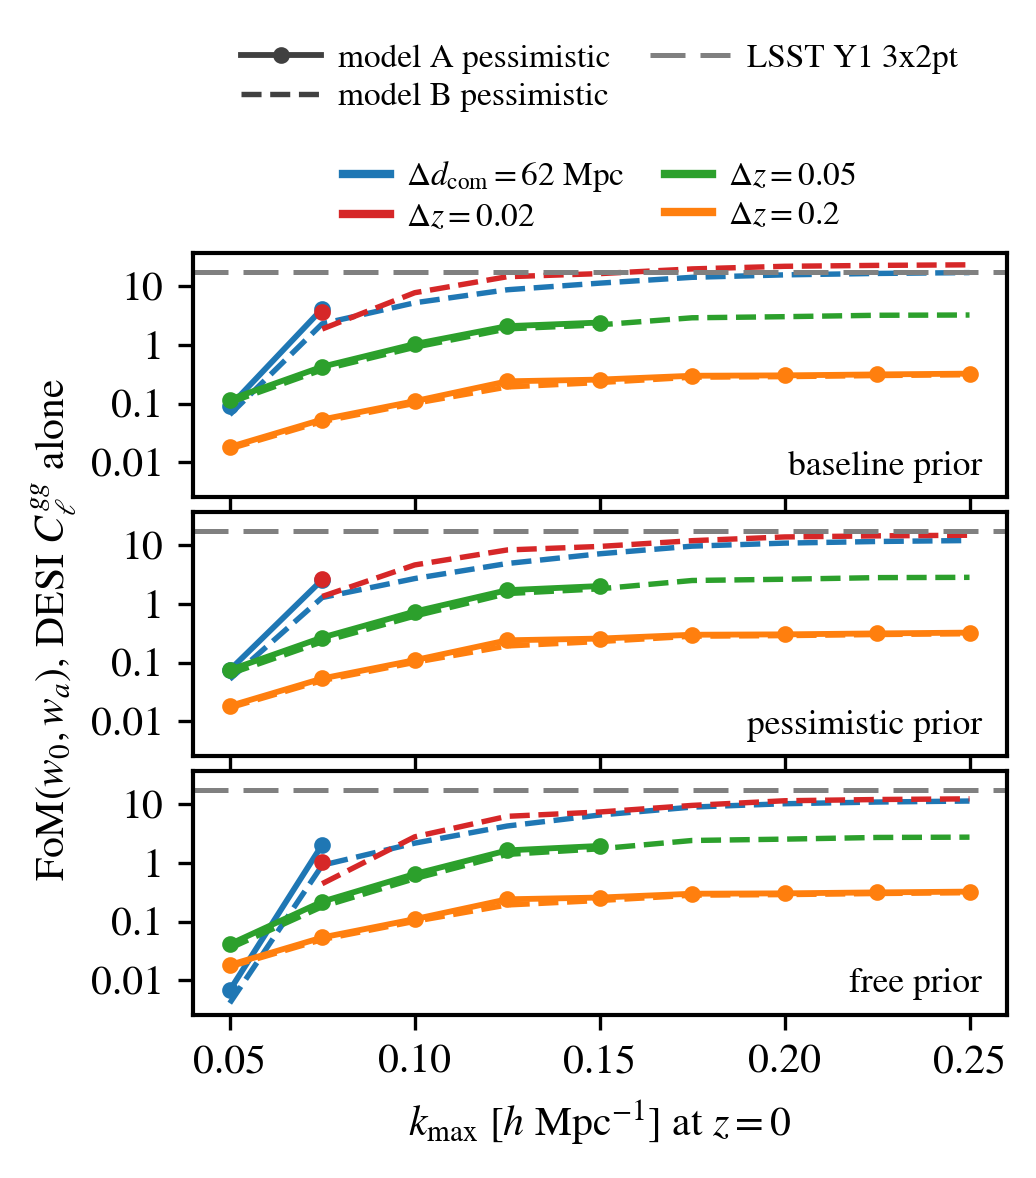

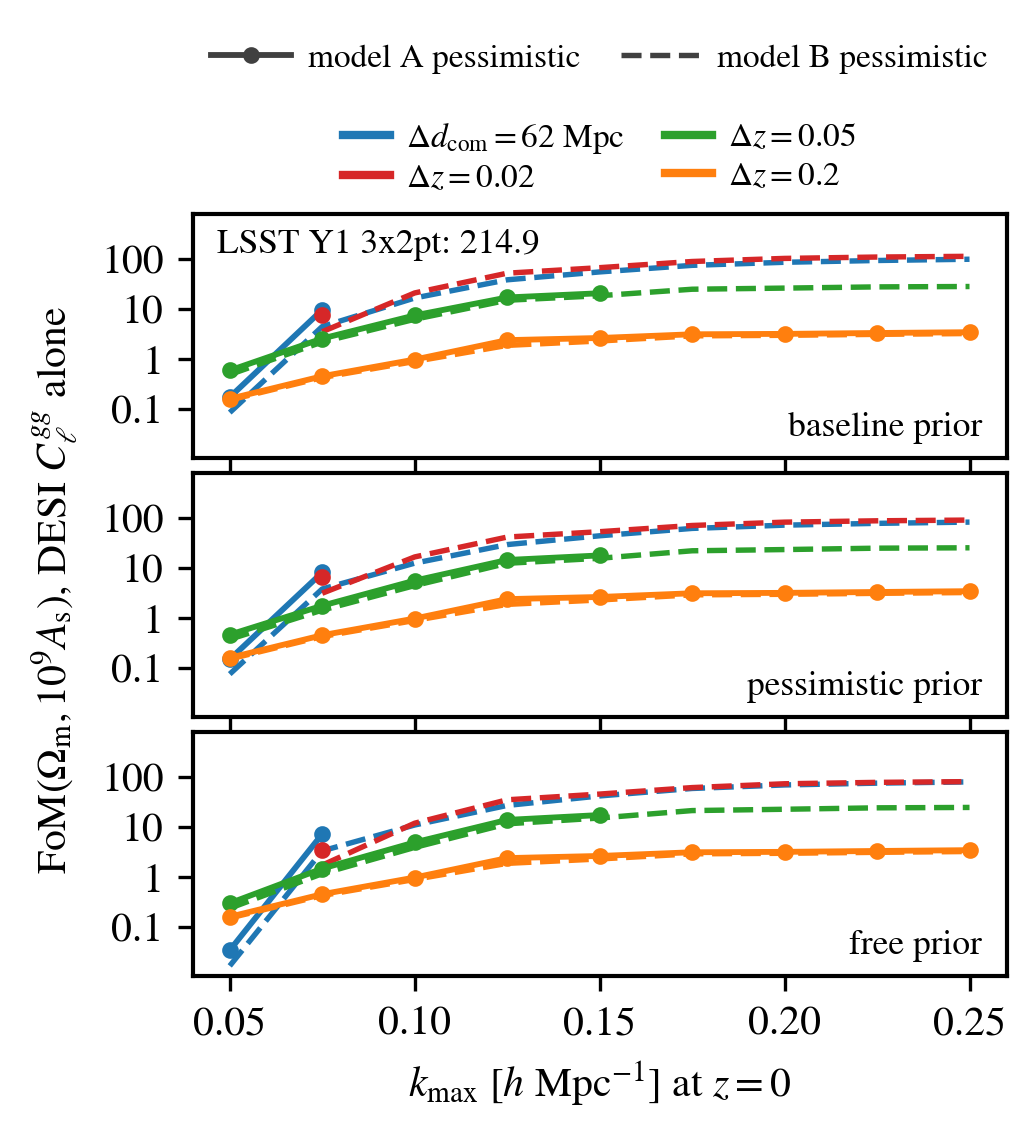

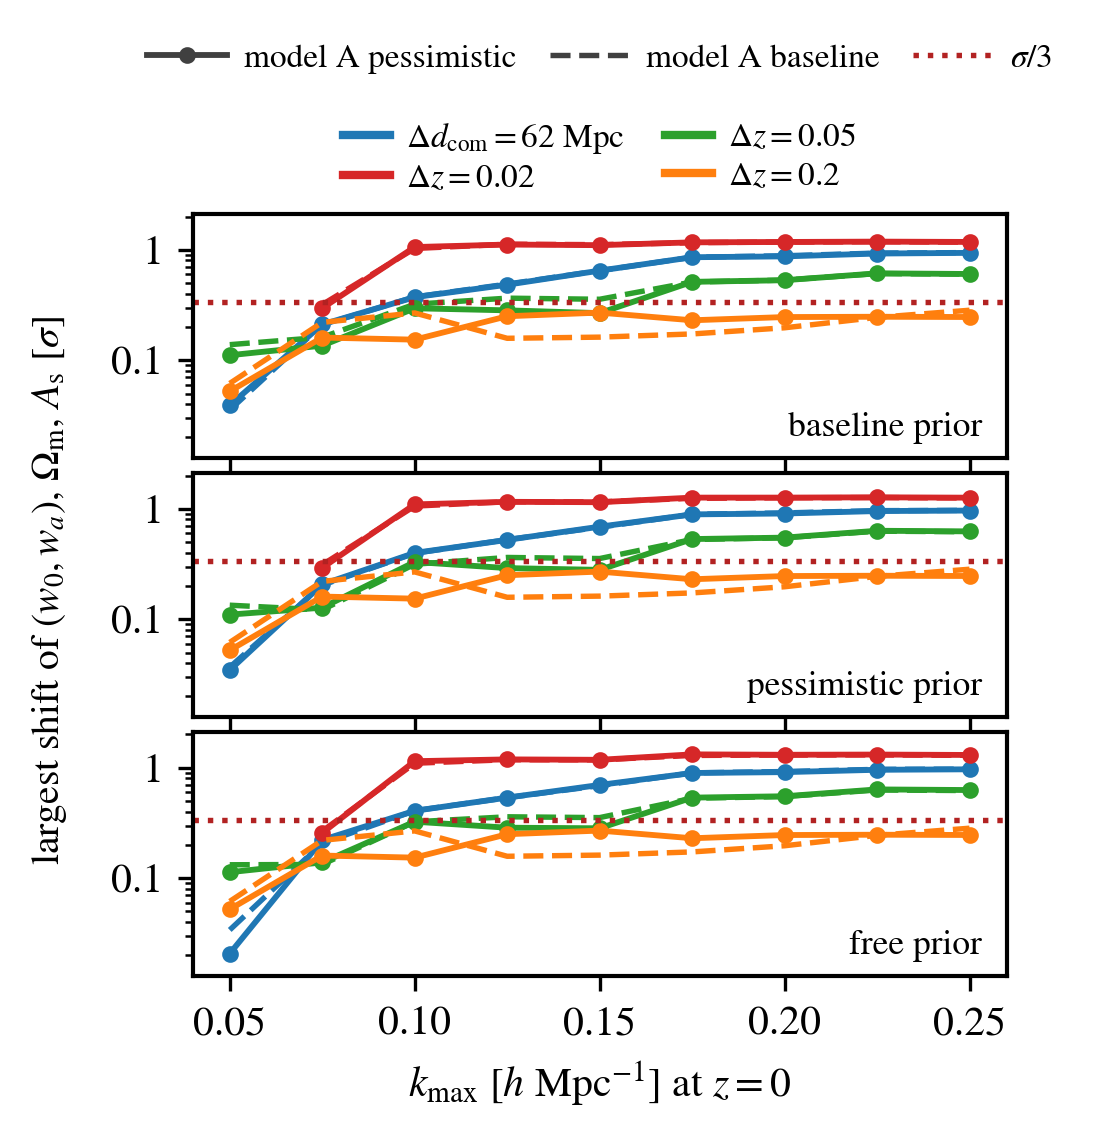

In [10]:
KMAX_LIST = [float(k) for k in KMAX_CUTS]


def per_cut(table, key, variant, prior, field=None):
    '''One entry per cut from a {(key, m, variant, prior): value} table (None: no fit).'''
    out = []
    for m in range(NK):
        entry = table[(key, m, variant, prior)]
        if entry is not None and field is not None:
            entry = entry[field]
        out.append(entry)
    return out


def layout_entry(key):
    '''The name, plotted label and color of one layout.'''
    return {'name': key, 'label': LAYOUT_LABELS[key], 'color': LAYOUT_COLORS[key]}


common = {'kmax_h_per_Mpc': KMAX_LIST, 'shift_threshold': SHIFT_THRESHOLD,
          'priors': FIT_PRIORS, 'prior_labels': PRIOR_LABELS,
          'prior_widths': {model: {**FIXED_WIDTHS[model],
                                   'counterterms': f'{COUNTERTERM_FRACTION}/k_max^2'}
                           for model in FIXED_WIDTHS}}
fom_data = {
    'about': ('Figures of merit of DESI C_gg alone against the scale cut k_max [h/Mpc; '
              'the z = 0 value of a per-bin cut at k_max/D(zbar_i), D the growth '
              'factor, by the UV-fraction criterion, alpha = 0.05, within the shipped '
              'mask]: fom = FoM(w0, wa) and fom_om_as = FoM(Omega_m, 10^9 A_s), each '
              'det(marginalized 2x2 covariance)^(-1/2), per layout, linear-bias prior '
              '(independent = free) and variant of the one-loop models A and B '
              '(notes/higher_order_bias); null where a cut leaves no fit. '
              'model_a_break: per model A variant and prior, the largest k_max at '
              'which the model A fits to every fixed model B truth shift (w0, wa), '
              'Omega_m and A_s by less than shift_threshold sigma, there and at every '
              'smaller cut (kmax null: the smallest fitted cut fails). The model A '
              'FoMs beyond it are kept: what extending model A would claim. LSST Y1 '
              '3x2pt references from the lsst_y1 project. Written by '
              'EXAMPLE_EVALUATE_FISHER_MODEL_B.ipynb.'),
    **common, 'variants': VARIANTS,
    'lsst_y1_3x2pt_fom': LSST_Y1_SRD_FOM,
    'lsst_y1_3x2pt_fom_om_as': LSST_Y1_SRD_FOM_OM_AS,
    'layouts': [{**layout_entry(key),
                 'fom': {v: {p: per_cut(FOM, key, v, p, 'fom') for p in FIT_PRIORS}
                         for v in VARIANTS},
                 'fom_om_as': {v: {p: per_cut(FOM, key, v, p, 'fom_om_as')
                                   for p in FIT_PRIORS}
                               for v in VARIANTS},
                 'model_a_break': {v: {p: BREAK[(key, v, p)] for p in FIT_PRIORS}
                                   for v in MODEL_A_VARIANTS}}
                for key in LAYOUTS],
}


def worst_per_cut(key, variant, prior):
    '''The largest shift over the truths of the break point, per cut (None: no fit).'''
    out = []
    for scores in per_cut(SCORES, key, variant, prior):
        out.append(None if scores is None else worst_score(scores)[0])
    return out


break_data = {
    'about': ('Shifts of model A fits (with SN0 and SN2 per group) to truths that carry '
              'model B\'s alpha_2 or model A\'s own terms at one sigma, by Fisher '
              'linear response, against the scale cut k_max [h/Mpc; the z = 0 value '
              'of a per-bin cut at k_max/D(zbar_i), D the growth factor, by the '
              'UV-fraction criterion, alpha = 0.05, within the shipped mask], per '
              'layout, model A variant and linear-bias prior (independent = free): '
              '(w0, wa) in units of the fit\'s ellipse, Omega_m and A_s in their own '
              'sigma. shift: the truths of the break point, the same in every bin: '
              'alpha_2 = +-12.5 h^-2 Mpc^2, and at model A\'s one-sigma widths SN2 = '
              '+-5 units of f_sat sigma_sat^2/nbar and the b2 and bs2 offsets +-(1, 0.5) '
              '(to first order). worst: the largest of these shifts. break: the '
              'largest k_max with worst below shift_threshold there and at every '
              'smaller fitted cut. prior_mismatch: a diagnostic outside the break '
              'point, the offsets at model B\'s widths, +-(2, 1). random_draws: 2000 '
              'draws of alpha_2 per group from model B baseline\'s prior, '
              'every other parameter from model A\'s: the mean and 16-84 percentiles '
              'of the shifts, sqrt(<chi^2>/n_dof) (stored as error_inflation; 1 for '
              'honest error bars) and the coverage, the probability that the truth '
              'falls inside the fit\'s one-sigma region (one_sigma for honest error '
              'bars). null: no fit. Written by EXAMPLE_EVALUATE_FISHER_MODEL_B.ipynb.'),
    **common, 'variants': MODEL_A_VARIANTS, 'truths': FIXED_TRUTHS,
    'mismatch_truths': MISMATCH_TRUTHS, 'truth_families': TRUTH_FAMILY,
    'params': ['w0wa', *SINGLE_PARAMS], 'random_families': RANDOM_FAMILIES,
    'n_draws': SCATTER_DRAWS, 'seed': SCATTER_SEED, 'one_sigma': ONE_SIGMA,
    'layouts': [{**layout_entry(key),
                 'shift': {v: {p: per_cut(SCORES, key, v, p) for p in FIT_PRIORS}
                           for v in MODEL_A_VARIANTS},
                 'worst': {v: {p: worst_per_cut(key, v, p) for p in FIT_PRIORS}
                           for v in MODEL_A_VARIANTS},
                 'break': {v: {p: BREAK[(key, v, p)] for p in FIT_PRIORS}
                           for v in MODEL_A_VARIANTS},
                 'prior_mismatch': {v: {p: per_cut(MISMATCH, key, v, p)
                                        for p in FIT_PRIORS}
                                    for v in MODEL_A_VARIANTS},
                 'random_draws': {v: {p: per_cut(RANDOM, key, v, p) for p in FIT_PRIORS}
                                  for v in MODEL_A_VARIANTS}}
                for key in LAYOUTS],
}

EXPORTS = [('fom_kmax_models', fom_data, ['fom_kmax_models', 'fom_kmax_models_om_as']),
           ('model_a_break', break_data, ['model_a_break'])]
for name, data, figures in EXPORTS:
    folder = NOTE_PLOTS + name
    script = folder + f'/plot_{name}.py'
    if not os.path.exists(script):
        raise RuntimeError(f'{script} is missing: the folder needs its plot script')
    with open(folder + '/data.json', 'w') as f:
        json.dump(data, f, indent=1)
    # the standalone redraw: isolated mode, and a RuntimeWarning (a NaN in a
    # reduction, say) stops the script
    subprocess.run([sys.executable, '-I', '-W', 'error::RuntimeWarning', script],
                   check=True)
    for figure in figures:
        display(Image(filename=f'{folder}/{figure}.png', width=460))

## 9. Conclusion

The printed tables and the two figures hold the three results:

1. **The break of model A** (section 7, `model_a_break.pdf`): $0.075$ on
   $\Delta d_\mathrm{com} = 62$ Mpc and $\Delta z = 0.02$, $0.1$ (model A baseline)
   or $0.15$ (model A pessimistic) on $\Delta z = 0.05$, every cut on
   $\Delta z = 0.2$, under every linear-bias prior. $\alpha_2$ sets it on the
   thin layouts, and model A's own cut, $0.075$, holds.
2. **The FoMs of models A and B** (section 6): model B pessimistic on the
   pessimistic prior reaches ${\rm FoM}(w_0, w_a) = 12.1$, $14.9$, $2.84$ and
   $0.311$ at $0.25$.
3. **The paper figure**: `notes/correlated_bias_prior_v2/plots/fom_kmax_models/`,
   whose `data.json` holds every FoM and break point it draws, and the model A
   FoMs beyond the break. Beyond $0.075$ on the thin layouts it is a figure of
   model B.

The random truths of section 7 test the error bars of model A when $\alpha_2$
scatters over model B's prior, which the break point does not
test: a fit can stay below $\sigma/3$ for every fixed truth while its error bars
are too small for the scatter of the truths. The prior-mismatch table of section
7 shows what model A's tighter offset priors cost when the calibrations scatter
as widely as model B allows.

The absolute FoMs depend on the covariance: Gaussian, computed at the model A
fiducial with its one-loop spectra, and the same for both models; the
comparisons between models, variants and priors hold it fixed.
Model B has no redshift-space one-loop terms here.

All $k_\mathrm{max}$ above are quoted at $z = 0$; each bin is cut by the
UV-fraction criterion at $k_\mathrm{max}/D(\bar z_i)$ ($\alpha = 0.05$) within the
shipped mask.